# TMDB Movie Data Analysis 2026
## مشروع تحليل بيانات الأفلام — Data Analytics Final Project

**الهدف:** فهم بيانات الأفلام وتنظيفها واستكشافها وتحليلها إحصائيًا وهندسة ميزاتها ثم بناء نماذج تعلم آلي قابلة للتفسير.


**مصدر البيانات:** [Full TMDB Movies Dataset 2024 (1M Movies) | Kaggle](https://www.kaggle.com/datasets/asaniczka/tmdb-movies-dataset-2023-930k-movies).

تتكون مجموعة بيانات **TMDB Movies Dataset** أكثر من **مليون فيلم** في الإصدار المشار إليه، وتضم معلومات تفصيلية عن الأفلام مثل **العنوان، تاريخ الإصدار، اللغة الأصلية، النوع، مدة الفيلم، التقييم ومتوسط عدد الأصوات، مستوى الشعبية، الميزانية، الإيرادات، شركات ودول الإنتاج، اللغات المستخدمة، الوصف والكلمات المفتاحية**، إضافة إلى معرفات مرتبطة بمنصات مثل TMDB وIMDb. ويتميز حجمها الكبير وتنوع متغيراتها بإتاحة إجراء تحليلات واسعة حول **إنتاج الأفلام، الأنواع واللغات، التقييمات والشعبية، والعلاقة بين الميزانية والإيرادات**، مما يجعلها مناسبة 




## منهجية التحليل ومبدأ إدارة البيانات الكبيرة
نستخدم البيانات الكاملة للإحصاءات الأساسية والجودة، وعينة تمثيلية ثابتة للرسوم الثقيلة، وعينة أصغر ومتوازنة للتعلم الآلي. لا تعني العينة اختلاق بيانات؛ بل توثيق واضح لحدود الموارد وقابلية إعادة الإنتاج.

## Quality-Control Summary

هذه النسخة تحافظ على التحليل الأصلي وتصلح نقاطًا منهجية مهمة: تدقيق duplicate IDs قبل التنظيف، فصل التواريخ المستقبلية عن التحليل التاريخي، التمييز بين الصفر وعدم توفر المعلومة، إنشاء مؤشرات الرصد، استخدام rating-supported subset، اختبار Mann–Whitney بمجموعتين غير فارغتين، فصل متغيرات ما قبل الإصدار عن متغيرات ما بعد الإصدار في Leakage Audit، وتنفيذ المعالجة داخل Pipelines بعد Train/Test Split. لا تُنسخ أي نتيجة رقمية مسبقة؛ كل الأرقام يعاد حسابها عند التشغيل.

## 02 — Environment Setup

In [1]:
import sys, os, re, json, ast, math, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr, spearmanr, mannwhitneyu, kruskal, chi2_contingency
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve, average_precision_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)
print('Python:', sys.version)
print('pandas:', pd.__version__, '| numpy:', np.__version__, '| sklearn:', sklearn.__version__)
print('Platform:', platform.platform())
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize']=(10,6)

Python: 3.12.3 (main, Jun 19 2026, 12:46:00) [GCC 13.3.0]
pandas: 3.0.5 | numpy: 2.5.1 | sklearn: 1.9.1
Platform: Linux-6.18.38+-x86_64-with-glibc2.39


## 03 — Dataset Acquisition

In [2]:
ROOT=Path('/home/ubuntu/tmdb_project')
DATA_DIR=ROOT/'data'
DATA_DIR.mkdir(exist_ok=True)
files=list(DATA_DIR.glob('*.csv'))
if not files:
    raise FileNotFoundError('لم يتم العثور على CSV محليًا. نزّل ملف Kaggle إلى data/ ثم أعد التشغيل.')
DATA_PATH=files[0]
print('Using:', DATA_PATH, 'size(MB)=', round(DATA_PATH.stat().st_size/1024**2,2))

Using: /home/ubuntu/tmdb_project/data/TMDB_movie_dataset_v11.csv size(MB)= 629.12


**ملاحظة عن المصدر:** اسم الملف الفعلي لا يُفترض مسبقًا؛ تم اكتشافه من مجلد البيانات بعد تنزيل المصدر العام. الملف المستخدم هو `TMDB_movie_dataset_v11.csv`.

## 04 — Dataset Overview

In [3]:
df=pd.read_csv(DATA_PATH, low_memory=False)
original_shape=df.shape
print('Rows, columns:', df.shape)
print('Memory (MB):', round(df.memory_usage(deep=True).sum()/1024**2,2))
display(df.head(3)); display(df.tail(3)); display(df.sample(3, random_state=RANDOM_STATE))

Rows, columns: (1495113, 24)


Memory (MB): 1603.91


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
1495110,910900,When Alone,0.0,0,Released,2021-09-19,0,4,False,NaN,...,כשלבד,A deep dive into this woman’s soul and an expl...,0.6000,/4lwqNA4fSeTZyuHWFTvb4Ocsq7e.jpg,NaN,Animation,NaN,Israel,NaN,NaN
1495111,910901,Beverley Hills Flop,0.0,0,Released,2021-12-01,0,9,False,NaN,...,Beverley Hills Flop,"A pop video send-up, in which nothing gets sta...",0.6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1495112,1769992,Smokee,0.0,0,Released,NaN,0,0,False,NaN,...,Smokee,A group attending a marriage counseling retrea...,0.0143,/eMgcmfix92a3npILrwSUm771IPP.jpg,"If you're on the weed, prepare to bleed!","Comedy, Horror",NaN,NaN,English,NaN


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
1488321,903402,Seadrift,0.0,0,Released,1976-01-01,0,15,False,NaN,...,Seadrift,Seadrift is based on a story The Shadow Over I...,0.6,/mnxh9LSD6jLBAVehs5Mh1wtyZss.jpg,NaN,NaN,NaN,Canada,NaN,NaN
249333,864113,Vazio,10.0,1,Released,NaN,0,0,False,/6RmSubooS2XYnyQlKYYQTrHxumu.jpg,...,Vazio,NaN,0.6,/4Qv5AFiU2XTs1YE6Cj6EGR5vlKg.jpg,NaN,"Fantasy, Horror",Nightopia Studios,Brazil,NaN,"video game, brazilian horror"
1357950,837017,Desert Dogs,0.0,0,Released,2020-10-14,0,20,False,/5SOy8v98QtRjiJwb3952zD2wBRi.jpg,...,Desert Dogs,Aya and Ibrahim both live from one moment to t...,0.6,/iWhO1cFxdr54NPou637BG4PrhSE.jpg,NaN,NaN,NaN,Switzerland,NaN,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1495113 entries, 0 to 1495112
Data columns (total 24 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   id                    1495113 non-null  int64  
 1   title                 1495094 non-null  str    
 2   vote_average          1495113 non-null  float64
 3   vote_count            1495113 non-null  int64  
 4   status                1495113 non-null  str    
 5   release_date          1142387 non-null  str    
 6   revenue               1495113 non-null  int64  
 7   runtime               1495113 non-null  int64  
 8   adult                 1495113 non-null  bool   
 9   backdrop_path         364600 non-null   str    
 10  budget                1495113 non-null  int64  
 11  homepage              152984 non-null   str    
 12  imdb_id               685912 non-null   str    
 13  original_language     1495113 non-null  str    
 14  original_title        1495094 non-null  str  

In [5]:
display(pd.DataFrame({'column':df.columns, 'dtype':df.dtypes.astype(str).values, 'non_null':df.notna().sum().values, 'unique':df.nunique(dropna=True).values}))

,column,dtype,non_null,unique
0,id,int64,1495113,1493757
1,title,str,1495094,1266548
2,vote_average,float64,1495113,5025
3,vote_count,int64,1495113,3598
4,status,str,1495113,6
5,release_date,str,1142387,43899
6,revenue,int64,1495113,14731
7,runtime,int64,1495113,836
8,adult,bool,1495113,2
9,backdrop_path,str,364600,360636


## 05 — Data Dictionary

In [6]:
dictionary=pd.DataFrame({
'Column':df.columns,
'Type':df.dtypes.astype(str).values,
'Meaning':['TMDB identifier','Movie title','Average user rating','Number of votes','Release status','Release date','Worldwide revenue','Runtime in minutes','Adult flag','Backdrop path','Production budget','Official homepage','IMDb identifier','Original language','Original title','Plot overview','TMDB popularity score','Poster path','Tagline','Genres','Production companies','Production countries','Spoken languages','Keywords'],
'Role':['ID','Text','Numerical target candidate','Numerical','Categorical','Date','Numerical target candidate','Numerical','Categorical','URL/path','Numerical','URL','ID','Categorical','Text','Text','Numerical','URL/path','Text','Multi-label categorical','Multi-label categorical','Multi-label categorical','Multi-label categorical','Multi-label categorical'],
'Missing %':(df.isna().mean()*100).round(2).values, 'Unique':df.nunique(dropna=True).values})
display(dictionary)

,Column,Type,Meaning,Role,Missing %,Unique
0,id,int64,TMDB identifier,ID,0.00,1493757
1,title,str,Movie title,Text,0.00,1266548
2,vote_average,float64,Average user rating,Numerical target candidate,0.00,5025
3,vote_count,int64,Number of votes,Numerical,0.00,3598
4,status,str,Release status,Categorical,0.00,6
5,release_date,str,Release date,Date,23.59,43899
6,revenue,int64,Worldwide revenue,Numerical target candidate,0.00,14731
7,runtime,int64,Runtime in minutes,Numerical,0.00,836
8,adult,bool,Adult flag,Categorical,0.00,2
9,backdrop_path,str,Backdrop path,URL/path,75.61,360636


### تصنيف الأعمدة
- **IDs:** `id`, `imdb_id`
- **Numerical:** ratings, votes, revenue, runtime, budget, popularity
- **Categorical:** status, adult, original_language
- **Dates:** release_date
- **Text:** title, original_title, overview, tagline, keywords
- **Multi-label:** genres, production_companies, production_countries, spoken_languages
- **URLs/paths:** homepage, poster_path, backdrop_path

## 06 — Data Quality Assessment

In [7]:
missing=(df.isna().sum().rename('missing_count').to_frame().assign(missing_pct=lambda x:(x.missing_count/len(df)*100).round(2)).sort_values('missing_pct',ascending=False))
display(missing)

,missing_count,missing_pct
homepage,1342129,89.77
tagline,1285780,86.00
keywords,1132045,75.72
backdrop_path,1130513,75.61
production_companies,867323,58.01
imdb_id,809201,54.12
production_countries,738023,49.36
spoken_languages,708812,47.41
genres,670397,44.84
poster_path,544817,36.44


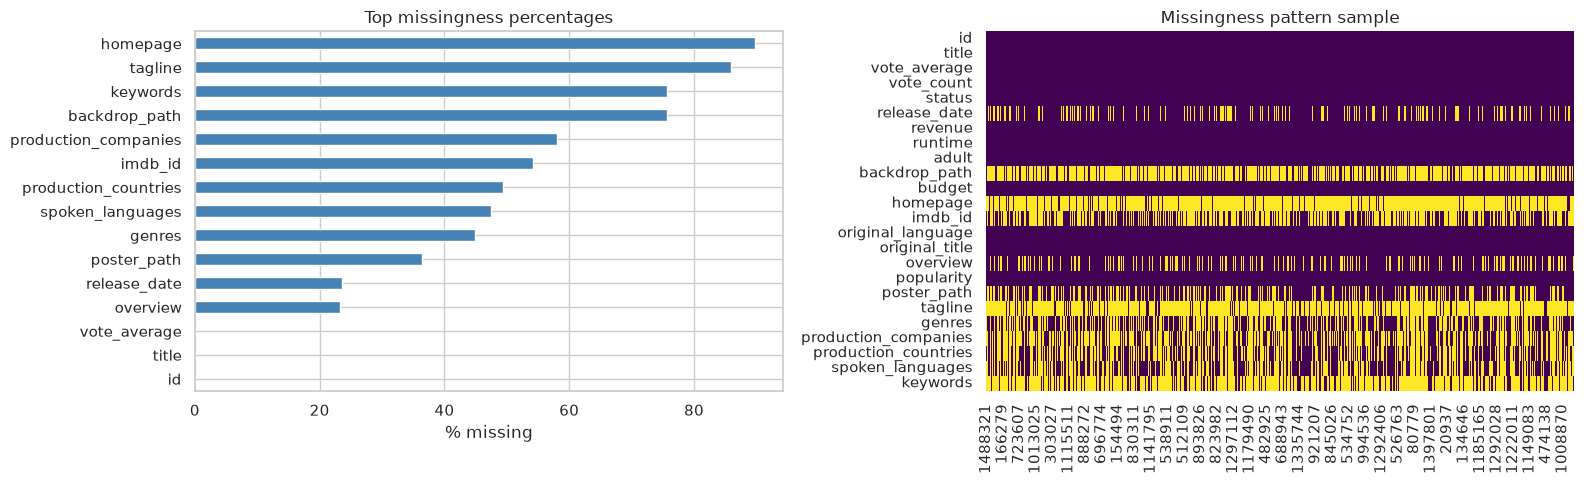

In [8]:
fig,ax=plt.subplots(1,2,figsize=(16,5))
missing.head(15).sort_values('missing_pct').plot.barh(y='missing_pct',ax=ax[0],legend=False,color='steelblue'); ax[0].set_title('Top missingness percentages'); ax[0].set_xlabel('% missing')
ms=df.isna().astype(int).sample(min(2000,len(df)),random_state=RANDOM_STATE); sns.heatmap(ms.iloc[:,:min(24,ms.shape[1])].T,cmap='viridis',cbar=False,ax=ax[1]); ax[1].set_title('Missingness pattern sample'); plt.tight_layout(); plt.show()

In [9]:
duplicate_rows=int(df.duplicated().sum()); duplicate_ids=int(df['id'].duplicated().sum())
print('Duplicate rows:', duplicate_rows, f'({duplicate_rows/len(df):.4%})')
print('Duplicate IDs:', duplicate_ids)

Duplicate rows: 384 (0.0257%)
Duplicate IDs: 1356


In [10]:
numeric_raw=['vote_average','vote_count','revenue','runtime','budget','popularity']
invalid=pd.DataFrame({
'negative':[(df[c]<0).sum() for c in numeric_raw],
'zero':[(df[c]==0).sum() for c in numeric_raw],
'column':numeric_raw}).set_index('column')
display(invalid)
print('Rating outside [0,10]:', ((df.vote_average<0)|(df.vote_average>10)).sum())
print('Runtime > 600 min:', (df.runtime>600).sum())

,negative,zero
column,,
vote_average,0,1134584
vote_count,0,1134306
revenue,1,1469739
runtime,1,472995
budget,0,1407247
popularity,0,273576


Rating outside [0,10]: 0
Runtime > 600 min: 821


In [11]:
for c in ['status','original_language','adult']:
    print('\n',c, df[c].value_counts(dropna=False).head(15).to_string())
print('Release date parse failures:', pd.to_datetime(df.release_date,errors='coerce').isna().sum())


 status status
Released           1437552
In Production        26285
Post Production      17220
Planned              12765
Rumored                908
Canceled               383

 original_language original_language
en    821255
fr     85914
es     77195
ja     69214
de     65830
zh     47197
pt     46442
it     29813
ru     29506
ko     16257
cs     12909
nl     11608
ar     10813
sv     10493
tr     10335

 adult adult
False    1347053
True      148060


Release date parse failures: 352726


### جودة البيانات — تفسير أولي
الأصفار في الميزانية والإيرادات غالبًا تعني قيمة غير متاحة أو غير موثقة، وليست بالضرورة صفرًا اقتصاديًا. لذلك لن نستخدمها في حساب ROI إلا بعد تحويلها إلى missing تحليليًا. القيم المتطرفة في الشعبية والإيرادات محفوظة للتحليل لأنها قد تمثل أفلامًا حقيقية، مع استخدام اللوغاريتم والعينات في الرسوم.

## 07–09 — Cleaning, Types, and Missing Values

In [12]:
clean=df.copy()
# Types
clean['release_date']=pd.to_datetime(clean['release_date'],errors='coerce')
for c in ['vote_average','vote_count','revenue','runtime','budget','popularity']:
    clean[c]=pd.to_numeric(clean[c],errors='coerce')
for c in ['title','overview','tagline','genres','production_companies','production_countries','spoken_languages','keywords','original_language','status']:
    clean[c]=clean[c].astype('string').str.strip()
# Domain rules: impossible negatives -> missing; zero financial values are unavailable for profitability analyses
for c in ['vote_average','vote_count','runtime','budget','revenue','popularity']:
    clean.loc[clean[c]<0,c]=np.nan
clean.loc[~clean['vote_average'].between(0,10), 'vote_average']=np.nan
clean.loc[clean['runtime']==0,'runtime']=np.nan
clean.loc[clean['budget']==0,'budget']=np.nan
clean.loc[clean['revenue']==0,'revenue']=np.nan
clean=clean.drop_duplicates(subset=['id'],keep='first').reset_index(drop=True)
print('Before:', original_shape, 'After:', clean.shape)
# Methodological audit: duplicate IDs, empty strings, statuses, dates, zeros, and future records
duplicate_id_groups=df[df['id'].duplicated(keep=False)].groupby('id').size().sort_values(ascending=False)
conflicting_duplicate_ids=int((df[df['id'].duplicated(keep=False)].groupby('id').nunique(dropna=False).max(axis=1)>1).sum()) if duplicate_id_groups.size else 0
clean['has_votes']=clean['vote_count'].fillna(0)>0
clean['has_budget']=clean['budget'].fillna(0)>0
clean['has_revenue']=clean['revenue'].fillna(0)>0
clean['has_runtime']=clean['runtime'].fillna(0)>0
clean['valid_release_date']=clean['release_date'].notna() & (clean['release_date']<=pd.Timestamp('2026-01-01')) & (clean['release_date']>=pd.Timestamp('1888-01-01'))
clean['future_release_record']=clean['release_date'].notna() & (clean['release_date']>pd.Timestamp('2026-01-01'))
status_table=clean['status'].fillna('Unknown').value_counts(dropna=False).rename_axis('status').reset_index(name='count'); status_table['percentage']=status_table['count']/len(clean)*100
quality_audit=pd.DataFrame([
 ['duplicate_rows','all',int(df.duplicated().sum()),df.duplicated().mean()*100,'Remove exact duplicate rows only'],
 ['duplicate_ids','id',int(df['id'].duplicated().sum()),df['id'].duplicated().mean()*100,'Inspect conflicts; retain documented first record'],
 ['conflicting_duplicate_ids','id',conflicting_duplicate_ids,conflicting_duplicate_ids/max(len(duplicate_id_groups),1)*100,'Document and deduplicate by id'],
 ['invalid_or_future_dates','release_date',int((~clean['valid_release_date']).sum()),(~clean['valid_release_date']).mean()*100,'Exclude from historical trends; retain in raw data'],
 ['zero_vote_average','vote_average',int((df.vote_average==0).sum()),(df.vote_average==0).mean()*100,'Treat as unsupported when vote_count is zero'],
 ['zero_budget','budget',int((df.budget==0).sum()),(df.budget==0).mean()*100,'Missing for ROI analysis'],
 ['zero_revenue','revenue',int((df.revenue==0).sum()),(df.revenue==0).mean()*100,'Missing for profitability analysis'],
 ['empty_overview','overview',int(clean.overview.fillna('').str.strip().eq('').sum()),clean.overview.fillna('').str.strip().eq('').mean()*100,'Empty string for text processing']
 ],columns=['Issue','Column','Count','Percentage','Treatment'])
print('Duplicate ID groups:',len(duplicate_id_groups),'conflicting groups:',conflicting_duplicate_ids)
print('Future records:',int(clean['future_release_record'].sum()),'invalid/non-historical:',int((~clean['valid_release_date']).sum()))
display(quality_audit); display(status_table)
rating_support_threshold=50
meaningful_summary=pd.DataFrame({'subset':['All records','Records with votes','Rating-supported (vote_count >= 50)','Known budget','Known revenue','Known runtime'],'count':[len(clean),int(clean.has_votes.sum()),int((clean.vote_count>=rating_support_threshold).sum()),int(clean.has_budget.sum()),int(clean.has_revenue.sum()),int(clean.has_runtime.sum())]})
print('Rating support threshold:',rating_support_threshold,'chosen as a transparent minimum engagement rule; vote_count quantiles:',clean.vote_count.quantile([.25,.5,.75,.9]).to_dict())
display(meaningful_summary)

print('Missing cells before:', int(df.isna().sum().sum()), 'after domain cleaning:', int(clean.isna().sum().sum()))
print('Duplicates after:', clean.duplicated(subset=['id']).sum())

Before: (1495113, 24) After: (1493757, 24)


Duplicate ID groups: 1009 conflicting groups: 969
Future records: 23774 invalid/non-historical: 375719


,Issue,Column,Count,Percentage,Treatment
0,duplicate_rows,all,384,0.025684,Remove exact duplicate rows only
1,duplicate_ids,id,1356,0.090695,Inspect conflicts; retain documented first record
2,conflicting_duplicate_ids,id,969,96.035679,Document and deduplicate by id
3,invalid_or_future_dates,release_date,375719,25.152619,Exclude from historical trends; retain in raw ...
4,zero_vote_average,vote_average,1134584,75.886170,Treat as unsupported when vote_count is zero
5,zero_budget,budget,1407247,94.123120,Missing for ROI analysis
6,zero_revenue,revenue,1469739,98.302871,Missing for profitability analysis
7,empty_overview,overview,348503,23.330635,Empty string for text processing


,status,count,percentage
0,Released,1436293,96.153056
1,In Production,26241,1.756711
2,Post Production,17191,1.150857
3,Planned,12743,0.853084
4,Rumored,908,0.060786
5,Canceled,381,0.025506


Rating support threshold: 50 chosen as a transparent minimum engagement rule; vote_count quantiles: {0.25: 0.0, 0.5: 0.0, 0.75: 0.0, 0.9: 3.0}


,subset,count
0,All records,1493757
1,Records with votes,360798
2,Rating-supported (vote_count >= 50),27981
3,Known budget,87757
4,Known revenue,25359
5,Known runtime,1021433


Missing cells before: 9929507 after domain cleaning: 13264004
Duplicates after: 0


In [13]:
quality_compare=pd.DataFrame({'Before Cleaning':[len(df),df.shape[1],int(df.isna().sum().sum()),int(df.duplicated().sum())], 'After Cleaning':[len(clean),clean.shape[1],int(clean.isna().sum().sum()),int(clean.duplicated().sum())]},index=['Rows','Columns','Missing cells','Duplicate rows'])
display(quality_compare)

,Before Cleaning,After Cleaning
Rows,1495113,1493757
Columns,24,30
Missing cells,9929507,13264004
Duplicate rows,384,0


In [14]:
# Missing treatment is feature-specific and mostly deferred to model pipelines
missing_policy=pd.DataFrame({'Feature':['budget','revenue','runtime','overview','tagline','genres','original_language'], 'Policy':['Keep missing; exclude from ROI','Keep missing; exclude from profitability','Keep missing; do not impute globally','Empty string only for TF-IDF','Empty string for text counts','Unknown category for parsing','Unknown category'], 'Reason':['Zero means unavailable','Zero means unavailable','Not reported for some records','Absence is informative','Optional marketing text','Multi-label missingness','Required for grouping']})
display(missing_policy)

,Feature,Policy,Reason
0,budget,Keep missing; exclude from ROI,Zero means unavailable
1,revenue,Keep missing; exclude from profitability,Zero means unavailable
2,runtime,Keep missing; do not impute globally,Not reported for some records
3,overview,Empty string only for TF-IDF,Absence is informative
4,tagline,Empty string for text counts,Optional marketing text
5,genres,Unknown category for parsing,Multi-label missingness
6,original_language,Unknown category,Required for grouping


## 10–11 — Outliers and Transformations

In [15]:
outlier_rows=[]
for c in ['budget','revenue','popularity','vote_count','runtime','vote_average']:
    x=clean[c].dropna(); q1,q3=x.quantile([.25,.75]); iqr=q3-q1; lo=q1-1.5*iqr; hi=q3+1.5*iqr
    out=((x<lo)|(x>hi)).sum(); z=(np.abs(stats.zscore(x))>3).sum() if len(x)>2 else 0
    outlier_rows.append([c,len(x),q1,q3,lo,hi,int(out),int(z),round(out/len(x)*100,2)])
outlier_table=pd.DataFrame(outlier_rows,columns=['feature','n','q1','q3','iqr_lower','iqr_upper','IQR_outliers','Z3_outliers','IQR_%'])
display(outlier_table)

,feature,n,q1,q3,iqr_lower,iqr_upper,IQR_outliers,Z3_outliers,IQR_%
0,budget,87757,150.0000,100000.00,-1.496250e+05,2.497750e+05,19265,1248,21.95
1,revenue,25359,1000.0000,12413769.00,-1.861815e+07,3.103292e+07,4267,389,16.83
2,popularity,1493757,0.0143,0.66,-9.542500e-01,1.628550e+00,122060,4487,8.17
3,vote_count,1493757,0.0000,0.00,0.000000e+00,0.000000e+00,360798,4435,24.15
4,runtime,1021433,14.0000,94.00,-1.060000e+02,2.140000e+02,12665,6836,1.24
5,vote_average,1493757,0.0000,0.00,0.000000e+00,0.000000e+00,360519,30183,24.14


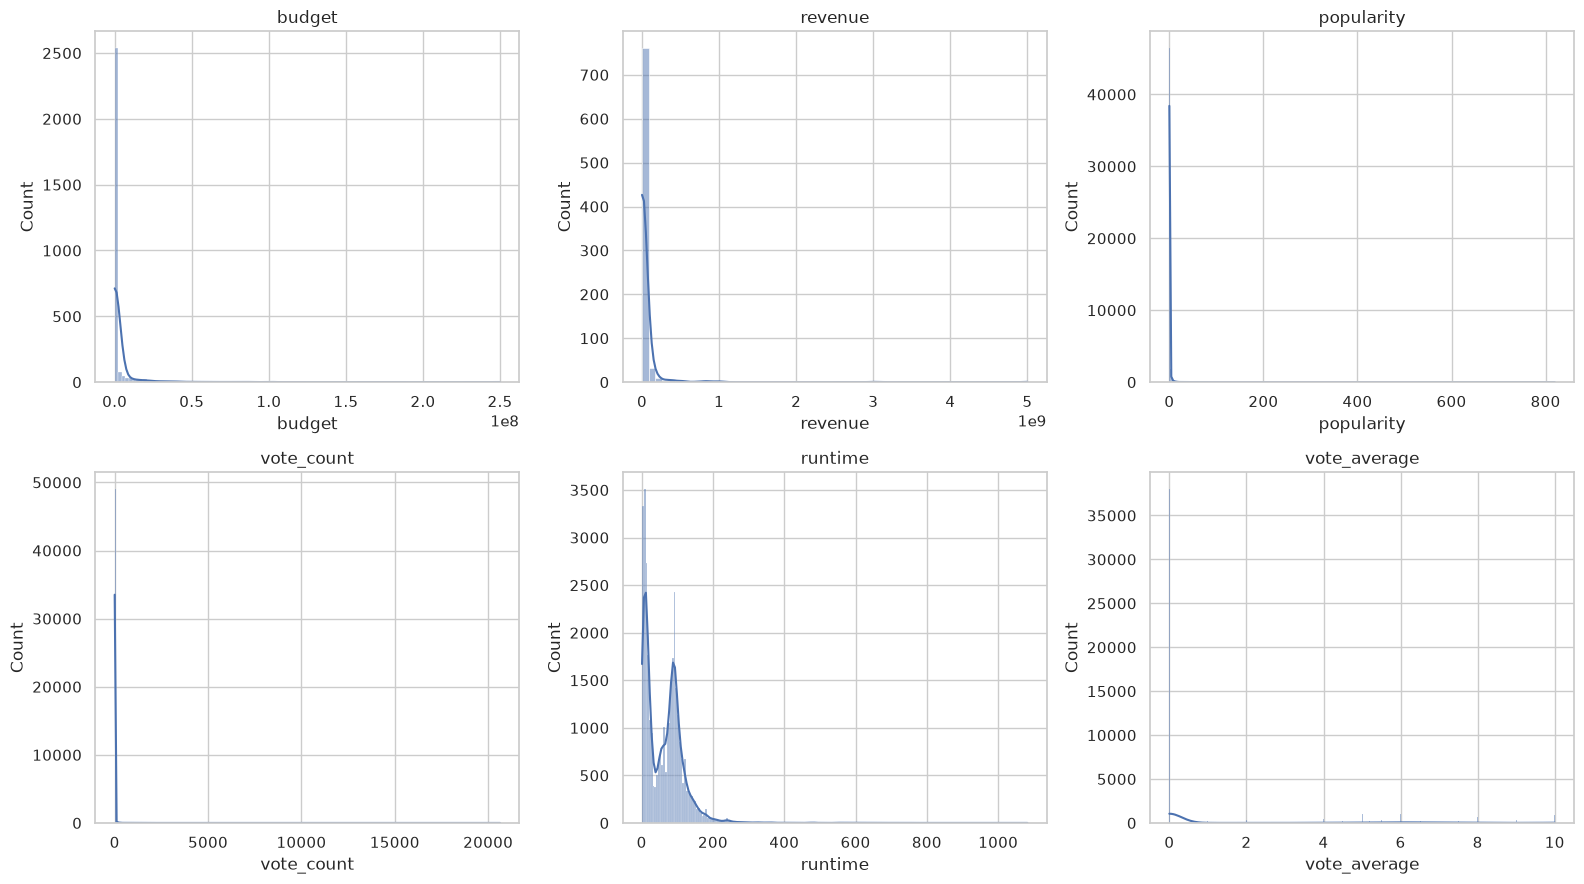

In [16]:
sample=clean.sample(min(50000,len(clean)),random_state=RANDOM_STATE)
fig,ax=plt.subplots(2,3,figsize=(16,9))
for a,c in zip(ax.ravel(),['budget','revenue','popularity','vote_count','runtime','vote_average']):
    sns.histplot(sample[c].dropna(),kde=True,ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

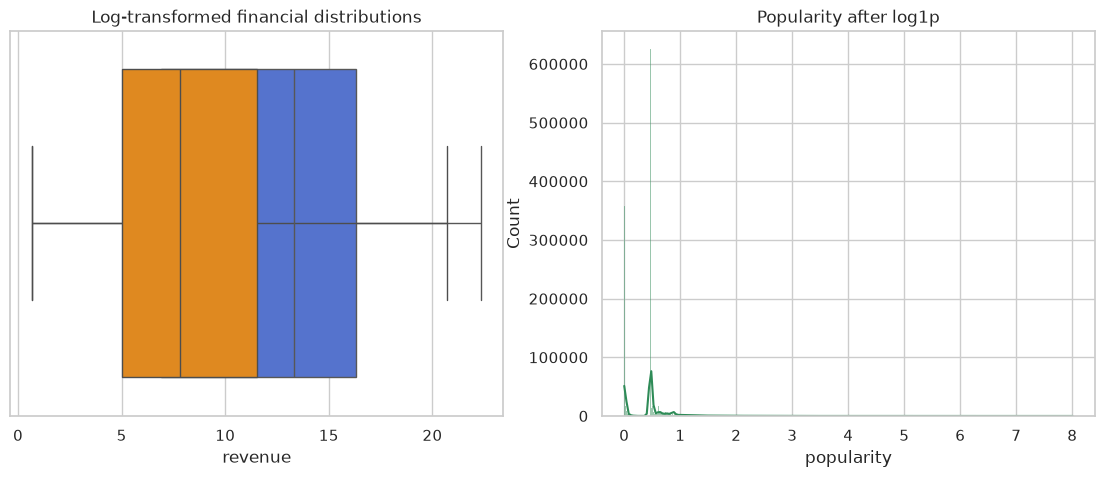

In [17]:
fig,ax=plt.subplots(1,2,figsize=(14,5))
for c,color in [('revenue','royalblue'),('budget','darkorange')]: sns.boxplot(x=np.log1p(clean[c].dropna()),ax=ax[0],color=color)
ax[0].set_title('Log-transformed financial distributions')
sns.histplot(np.log1p(clean['popularity'].dropna()),kde=True,ax=ax[1],color='seagreen'); ax[1].set_title('Popularity after log1p'); plt.show()

**قرار المعالجة:** لا نحذف القيم المتطرفة تلقائيًا؛ الإيرادات والميزانيات ذات الانحراف العالي قد تكون أحداثًا حقيقية. نستخدم `log1p` للعرض والنمذجة عند الحاجة، وRobustScaler للنماذج الحساسة، ونستبعد فقط القيم غير الممكنة التي خالفت المجال المنطقي.

## 12 — Univariate Analysis

In [18]:
stats_cols=['budget','revenue','popularity','vote_average','vote_count','runtime']
univariate=clean[stats_cols].describe(percentiles=[.01,.25,.5,.75,.99]).T
univariate['variance']=clean[stats_cols].var(); univariate['skewness']=clean[stats_cols].skew(); univariate['kurtosis']=clean[stats_cols].kurt(); univariate['mode']=clean[stats_cols].mode().iloc[0]
display(univariate.round(3))

,count,mean,std,min,1%,25%,50%,75%,99%,max,variance,skewness,kurtosis,mode
budget,87757.0,3.921404e+06,2.140544e+07,1.0,1.0,150.000,2500.0,100000.00,8.500000e+07,1.000000e+09,4.581927e+14,16.483,478.521,100.0
revenue,25359.0,3.580808e+07,1.478159e+08,1.0,1.0,1000.000,602042.0,12413769.00,6.729141e+08,5.000000e+09,2.184954e+16,13.159,300.324,1.0
popularity,1493757.0,9.620000e-01,6.638000e+00,0.0,0.0,0.014,0.6,0.66,1.045400e+01,2.994357e+03,4.405700e+01,197.281,64108.424,0.6
vote_average,1493757.0,1.489000e+00,2.819000e+00,0.0,0.0,0.000,0.0,0.00,1.000000e+01,1.000000e+01,7.944000e+00,1.593,1.048,0.0
vote_count,1493757.0,1.436600e+01,2.779560e+02,0.0,0.0,0.000,0.0,0.00,1.380000e+02,3.449500e+04,7.725970e+04,46.971,3019.278,0.0
runtime,1021433.0,6.312300e+01,6.385700e+01,1.0,1.0,14.000,60.0,94.00,2.340000e+02,1.440000e+04,4.077677e+03,35.564,6400.891,90.0


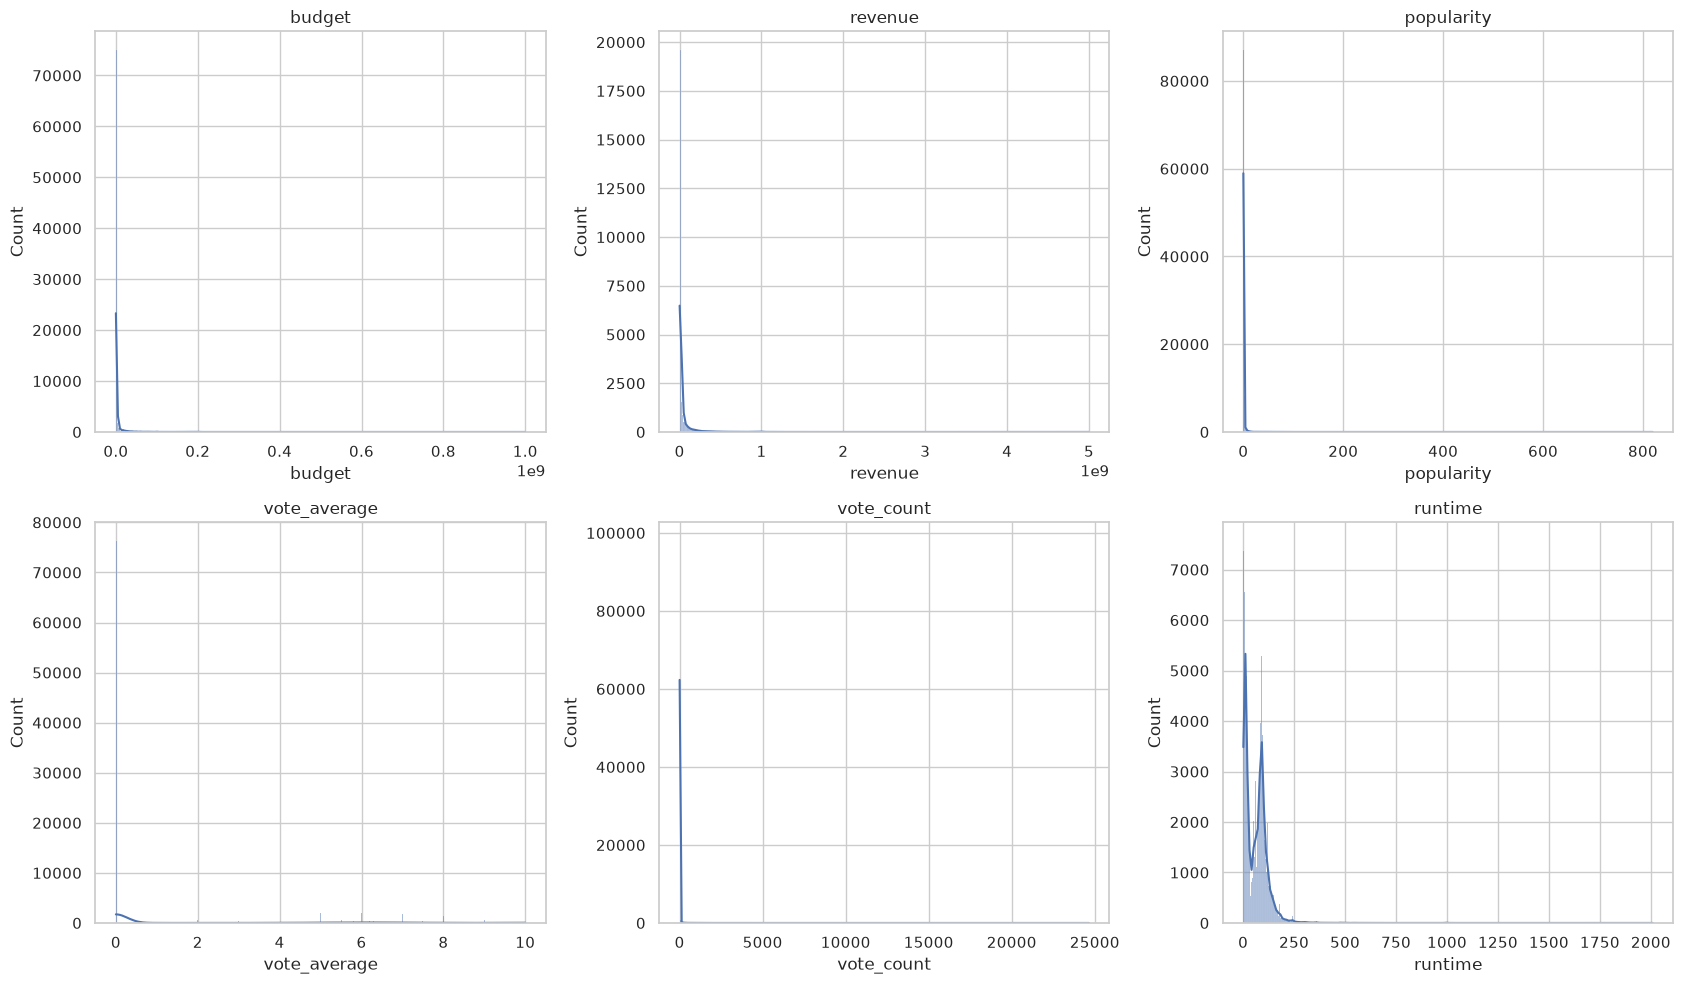

In [19]:
fig,ax=plt.subplots(2,3,figsize=(17,10))
for a,c in zip(ax.ravel(),stats_cols): sns.histplot(clean[c].dropna().sample(min(100000,clean[c].notna().sum()),random_state=RANDOM_STATE),kde=True,ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

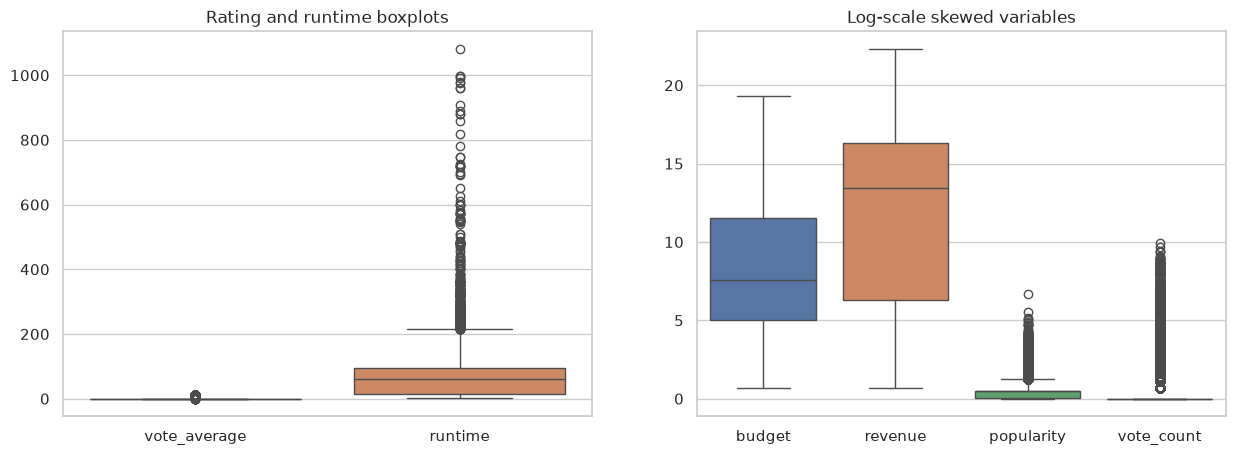

In [20]:
fig,ax=plt.subplots(1,2,figsize=(15,5))
sns.boxplot(data=sample[['vote_average','runtime']],ax=ax[0]); ax[0].set_title('Rating and runtime boxplots')
sns.boxplot(data=np.log1p(sample[['budget','revenue','popularity','vote_count']]),ax=ax[1]); ax[1].set_title('Log-scale skewed variables')
plt.show()

## 13 — Categorical and Multi-label Analysis

In [21]:
for c in ['status','original_language','adult']:
    t=clean[c].fillna('Unknown').value_counts().head(15).to_frame('count'); t['pct']=t['count']/len(clean)*100
    print('---',c); display(t.round(2))

--- status


,count,pct
status,,
Released,1436293,96.15
In Production,26241,1.76
Post Production,17191,1.15
Planned,12743,0.85
Rumored,908,0.06
Canceled,381,0.03


--- original_language


,count,pct
original_language,,
en,820431,54.92
fr,85849,5.75
es,77140,5.16
ja,69148,4.63
de,65784,4.4
zh,47164,3.16
pt,46402,3.11
it,29792,1.99
ru,29472,1.97


--- adult


,count,pct
adult,,
False,1345849,90.1
True,147908,9.9


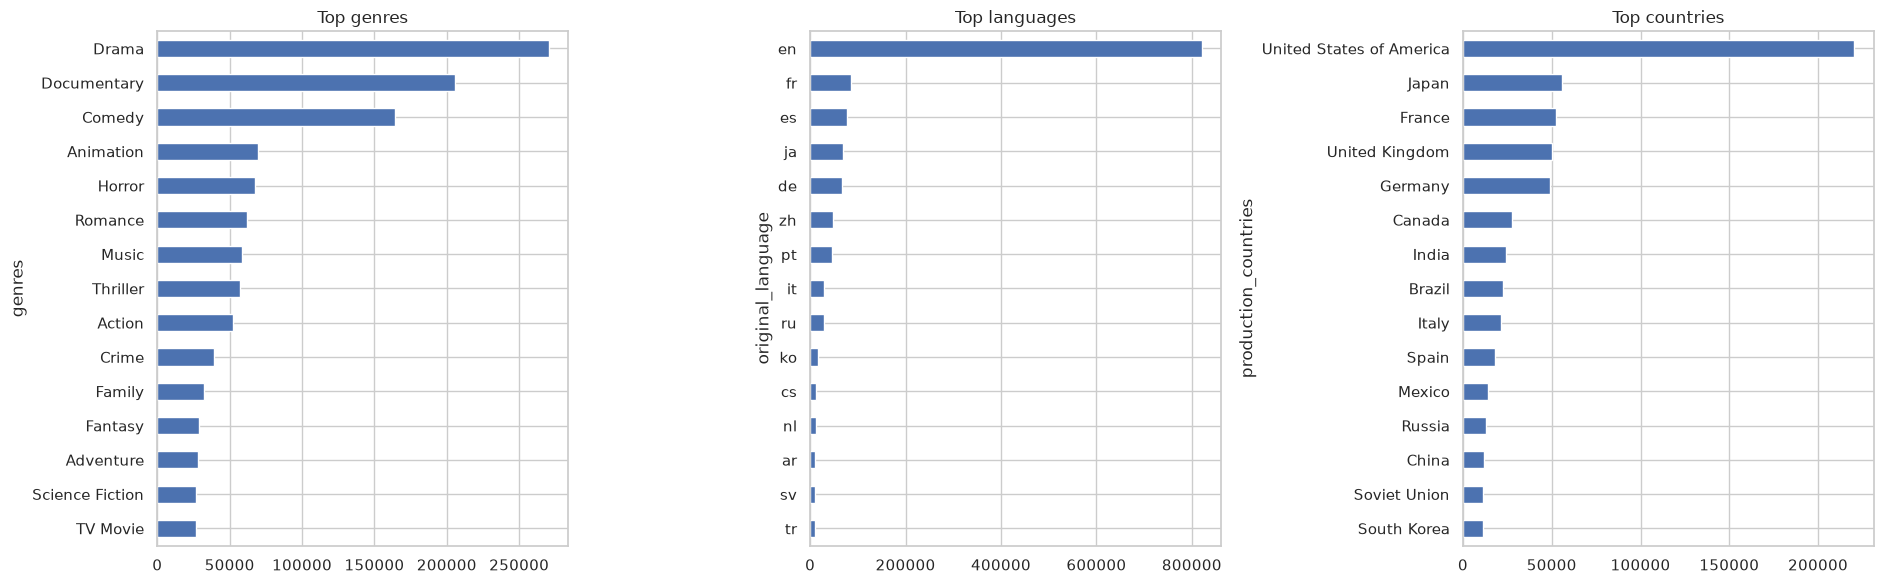

In [22]:
def split_labels(x):
    if pd.isna(x) or str(x).strip()=='' : return []
    return [v.strip() for v in str(x).split(',') if v.strip()]
def explode_counts(frame,col):
    return frame[col].fillna('').map(split_labels).explode().dropna().value_counts()
genre_counts=explode_counts(clean,'genres'); lang_counts=clean['original_language'].fillna('Unknown').value_counts(); country_counts=explode_counts(clean,'production_countries')
fig,ax=plt.subplots(1,3,figsize=(19,6))
genre_counts.head(15).sort_values().plot.barh(ax=ax[0],title='Top genres'); lang_counts.head(15).sort_values().plot.barh(ax=ax[1],title='Top languages'); country_counts.head(15).sort_values().plot.barh(ax=ax[2],title='Top countries'); plt.tight_layout(); plt.show()

## 14–17 — Bivariate, Multivariate, and Correlation Analysis

In [23]:
clean['profit']=clean['revenue']-clean['budget']
clean['roi']=clean['profit']/clean['budget']
clean.loc[clean['budget'].isna(),'roi']=np.nan
clean['genre_count']=clean['genres'].fillna('').map(lambda x:len(split_labels(x)))
clean['overview_length']=clean['overview'].fillna('').str.len(); clean['overview_word_count']=clean['overview'].fillna('').str.split().str.len()
clean['tagline_length']=clean['tagline'].fillna('').str.len(); clean['tagline_word_count']=clean['tagline'].fillna('').str.split().str.len()
for c in ['keywords','spoken_languages','production_companies','production_countries']:
    clean[c+'_count']=clean[c].fillna('').map(lambda x:len(split_labels(x)))
analysis_date=clean['release_date'].where(clean['valid_release_date'])
clean['release_year']=analysis_date.dt.year; clean['year']=clean['release_year']; clean['month']=analysis_date.dt.month; clean['quarter']=analysis_date.dt.quarter; clean['day_of_week']=analysis_date.dt.dayofweek; clean['release_decade']=(clean.year//10*10)
clean['movie_age']=np.where(clean['valid_release_date'], pd.Timestamp('2026-01-01').year-clean.year, np.nan)
print(clean[['profit','roi','genre_count','overview_word_count','movie_age']].describe().round(2))

             profit           roi  genre_count  overview_word_count  \
count  1.832500e+04  1.832500e+04   1493757.00           1493757.00   
mean   3.125091e+07  9.313192e+05         0.84                34.37   
std    1.520068e+08  5.457361e+07         0.97                36.11   
min   -9.000000e+08 -1.000000e+00         0.00                 0.00   
25%   -1.000000e+02 -3.000000e-01         0.00                 3.00   
50%    1.190000e+02  4.000000e-01         1.00                25.00   
75%    7.308964e+06  2.690000e+00         1.00                52.00   
max    5.000000e+09  5.000000e+09        19.00               231.00   

        movie_age  
count  1118038.00  
mean        25.04  
std         26.48  
min          0.00  
25%          7.00  
50%         15.00  
75%         35.00  
max        138.00  


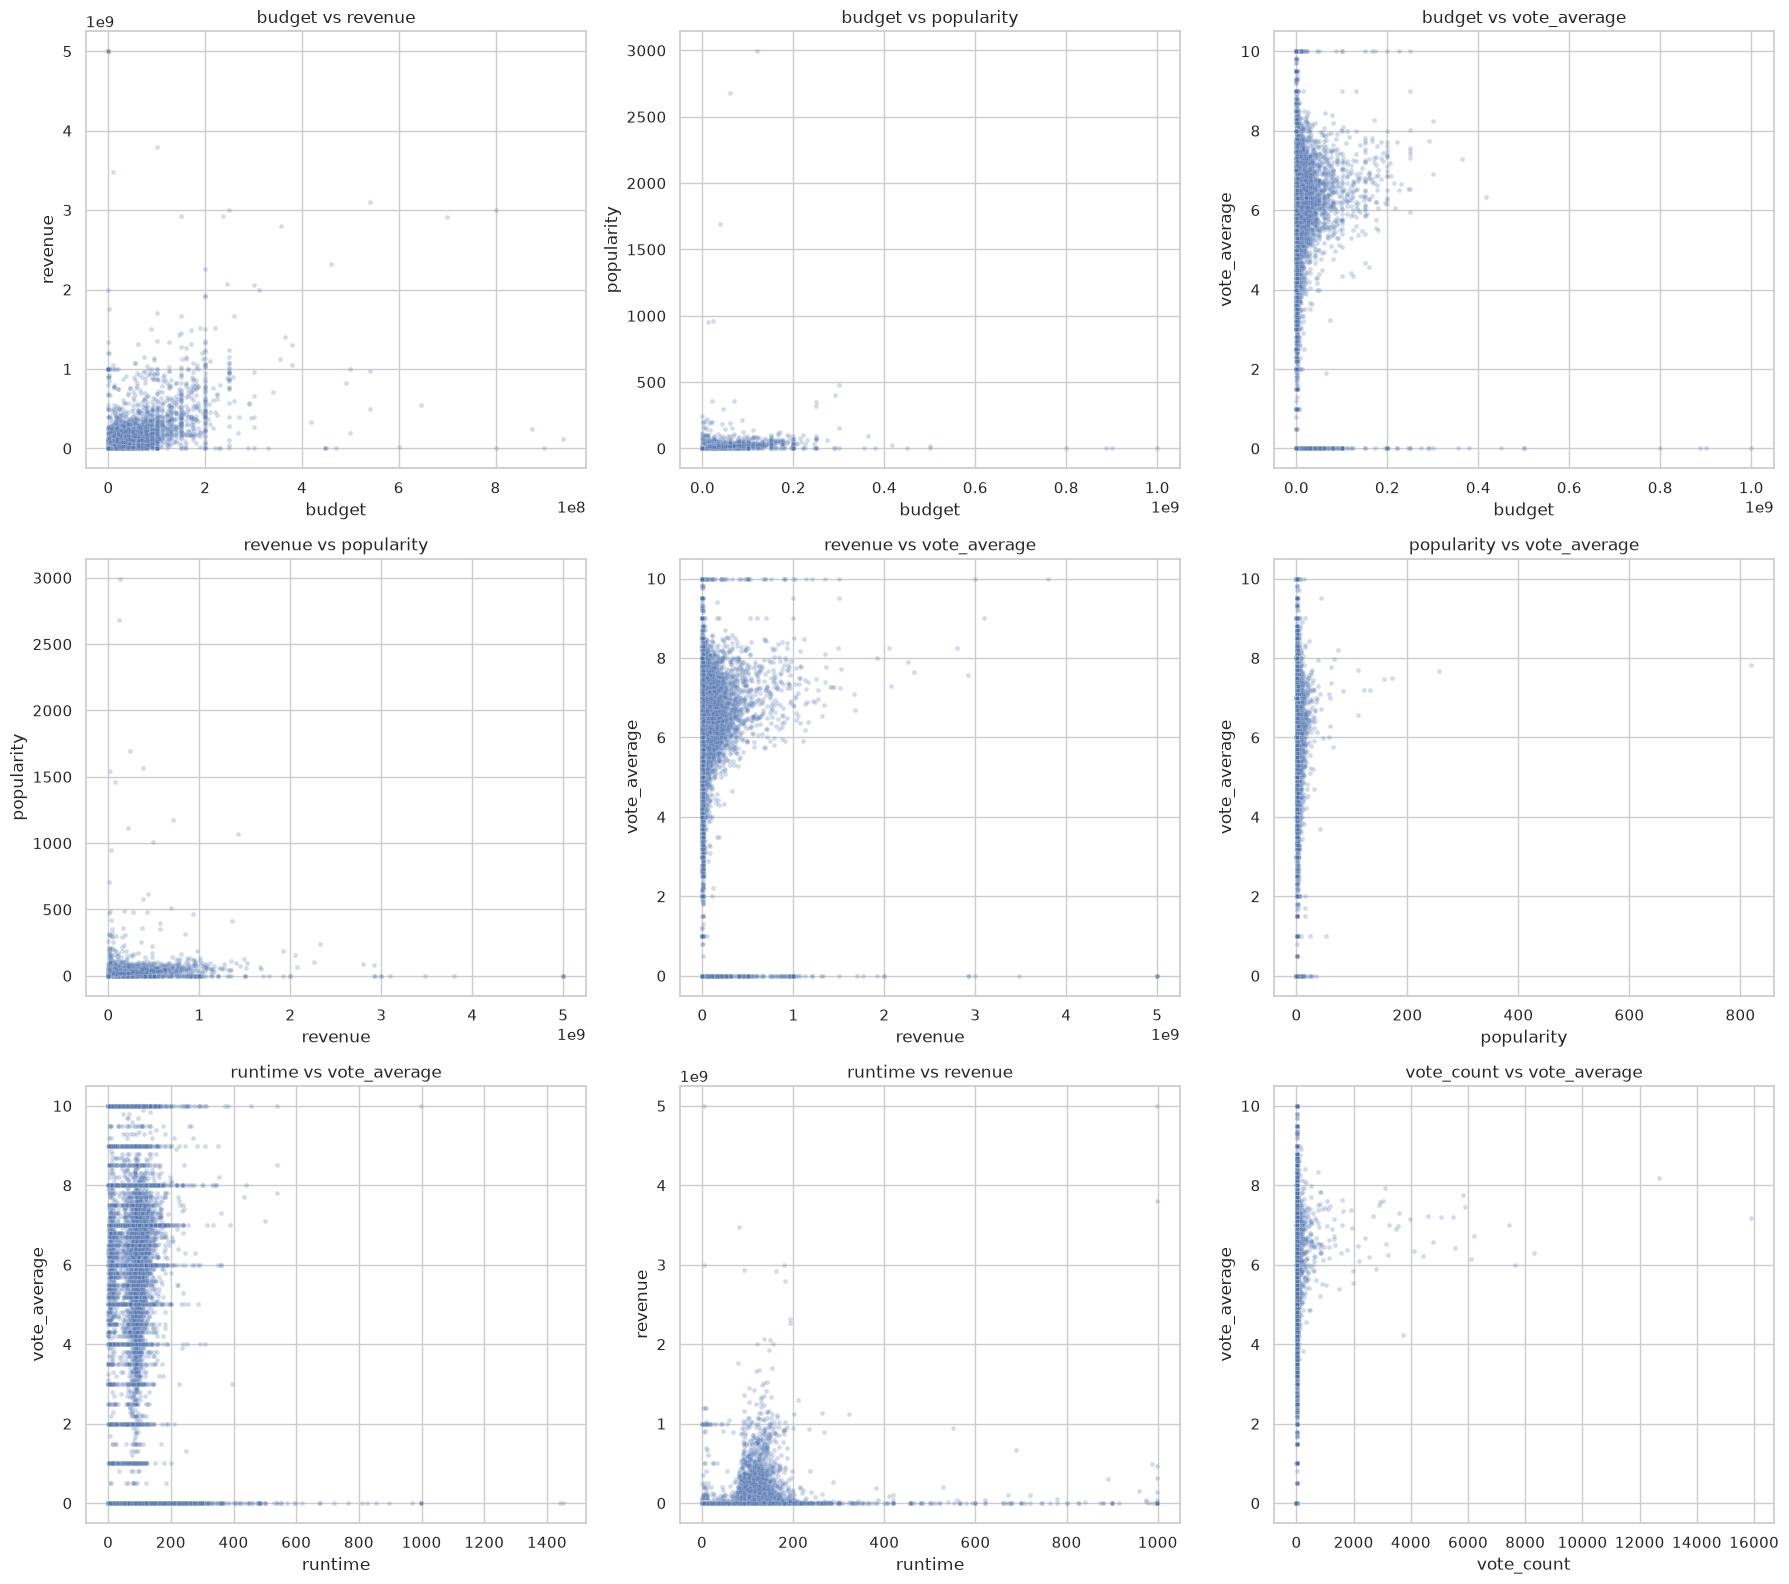

In [24]:
pairs=[('budget','revenue'),('budget','popularity'),('budget','vote_average'),('revenue','popularity'),('revenue','vote_average'),('popularity','vote_average'),('runtime','vote_average'),('runtime','revenue'),('vote_count','vote_average')]
fig,ax=plt.subplots(3,3,figsize=(18,16))
for a,(x,y) in zip(ax.ravel(),pairs):
    s=clean[[x,y]].dropna().sample(min(30000,clean[[x,y]].dropna().shape[0]),random_state=RANDOM_STATE); sns.scatterplot(data=s,x=x,y=y,alpha=.25,s=12,ax=a); a.set_title(f'{x} vs {y}')
plt.tight_layout(); plt.show()

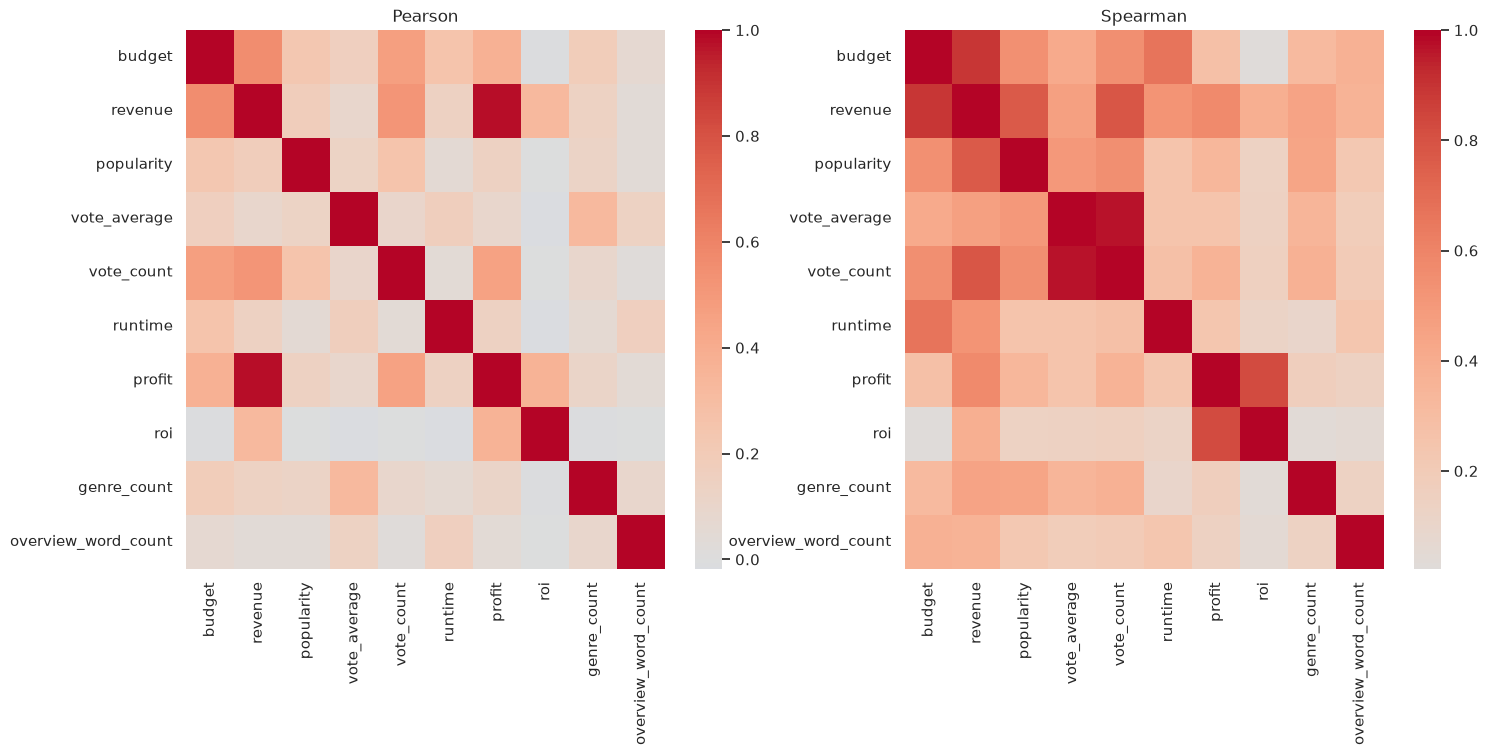

Correlation is association, not causation.


In [25]:
corr_cols=['budget','revenue','popularity','vote_average','vote_count','runtime','profit','roi','genre_count','overview_word_count']
pearson=clean[corr_cols].corr(method='pearson'); spearman=clean[corr_cols].corr(method='spearman')
fig,ax=plt.subplots(1,2,figsize=(17,7)); sns.heatmap(pearson,center=0,cmap='coolwarm',ax=ax[0]); ax[0].set_title('Pearson'); sns.heatmap(spearman,center=0,cmap='coolwarm',ax=ax[1]); ax[1].set_title('Spearman'); plt.show()
print('Correlation is association, not causation.')

,movie_count,avg_revenue,median_revenue,avg_rating,avg_budget,avg_popularity,avg_profit,median_roi,avg_runtime
genre,,,,,,,,,
Drama,270408,2.714577e+07,1522000.0,2.51,4007412.23,1.64,2.317498e+07,0.33,73.46
Documentary,205773,8.792280e+06,5000.0,1.67,713520.12,0.70,8.552167e+06,0.00,55.00
Comedy,164299,3.788917e+07,3004541.0,2.81,5507123.79,1.80,3.363608e+07,0.75,65.81
Animation,69457,8.153851e+07,5547663.5,2.04,13568039.54,1.49,8.438892e+07,0.62,22.95
Horror,67612,2.499692e+07,636990.0,2.14,1952661.53,1.93,2.282918e+07,0.57,55.51
Romance,61831,3.091968e+07,3735789.5,3.03,6106299.44,2.34,2.771677e+07,0.82,86.55
Music,58696,3.217670e+07,870162.0,2.36,3689808.86,0.95,3.201044e+07,0.67,77.14
Thriller,57299,4.245319e+07,3684835.5,3.01,6651940.73,3.15,3.430487e+07,0.52,74.88
Action,51967,8.330916e+07,8092916.0,3.13,17711813.51,3.63,6.959471e+07,0.75,90.39


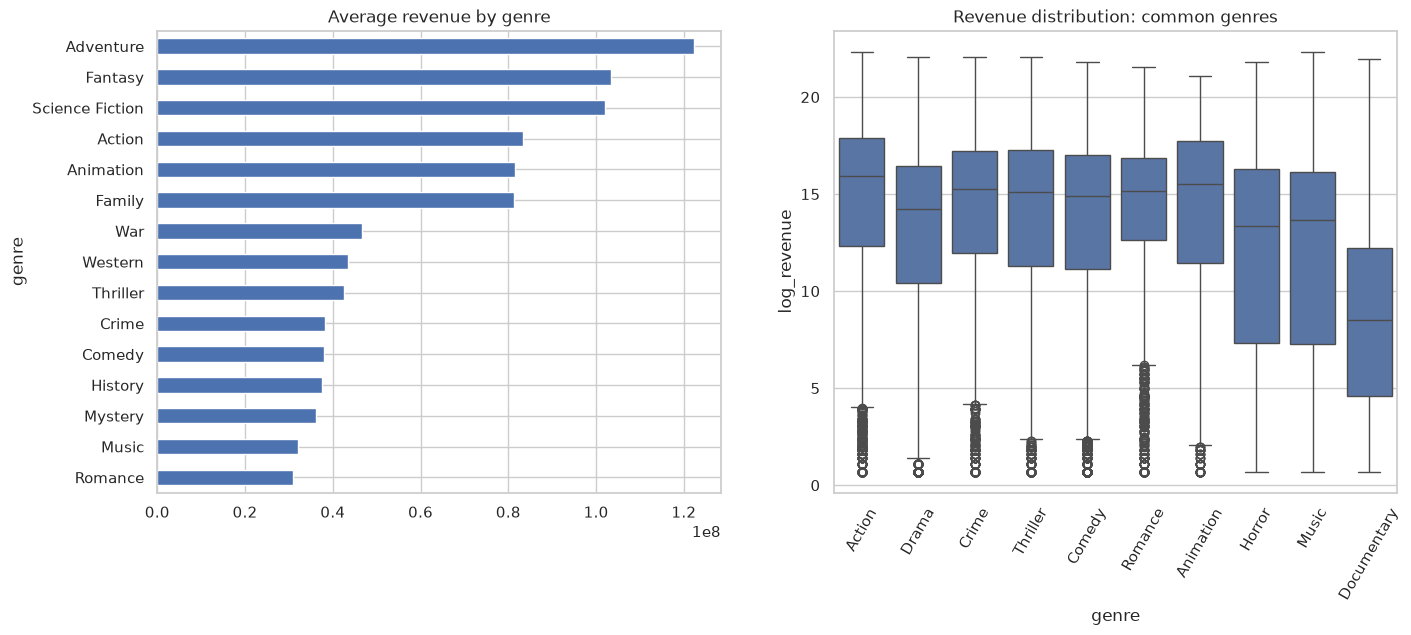

In [26]:
# Revenue/rating by genre with minimum sample size
genre_long=clean[['id','genres','revenue','budget','vote_average','popularity','profit','roi','runtime']].copy().assign(genre=lambda x:x.genres.map(lambda z:split_labels(z))).explode('genre').reset_index(drop=True)
genre_summary=genre_long.groupby('genre').agg(movie_count=('id','nunique'),avg_revenue=('revenue','mean'),median_revenue=('revenue','median'),avg_rating=('vote_average','mean'),avg_budget=('budget','mean'),avg_popularity=('popularity','mean'),avg_profit=('profit','mean'),median_roi=('roi','median'),avg_runtime=('runtime','mean')).query('movie_count>=100').sort_values('movie_count',ascending=False)
display(genre_summary.head(20).round(2))
plot_genres=genre_summary.head(10).index; genre_plot=genre_long[genre_long.genre.isin(plot_genres)].copy(); genre_plot['log_revenue']=np.log1p(genre_plot['revenue'])
fig,ax=plt.subplots(1,2,figsize=(16,6)); genre_summary.sort_values('avg_revenue').tail(15).avg_revenue.plot.barh(ax=ax[0],title='Average revenue by genre'); sns.boxplot(data=genre_plot,x='genre',y='log_revenue',ax=ax[1]); ax[1].tick_params(axis='x',rotation=60); ax[1].set_title('Revenue distribution: common genres'); plt.show()

## 18 — Statistical Analysis

In [27]:
# Pearson and Spearman significance for key associations
tests=[]
for x,y in [('budget','revenue'),('vote_count','vote_average'),('popularity','vote_average'),('runtime','vote_average')]:
    z=clean[[x,y]].dropna(); pr,pp=pearsonr(z[x],z[y]); sr,sp=spearmanr(z[x],z[y]); tests += [[x,y,'Pearson',pr,pp],[x,y,'Spearman',sr,sp]]
test_table=pd.DataFrame(tests,columns=['x','y','test','statistic','p_value']); test_table['conclusion']=np.where(test_table.p_value<.05,'Reject H0 at alpha=.05','Do not reject H0 at alpha=.05'); display(test_table.round(6))

,x,y,test,statistic,p_value,conclusion
0,budget,revenue,Pearson,0.560444,0.0,Reject H0 at alpha=.05
1,budget,revenue,Spearman,0.895326,0.0,Reject H0 at alpha=.05
2,vote_count,vote_average,Pearson,0.097932,0.0,Reject H0 at alpha=.05
3,vote_count,vote_average,Spearman,0.970885,0.0,Reject H0 at alpha=.05
4,popularity,vote_average,Pearson,0.129510,0.0,Reject H0 at alpha=.05
5,popularity,vote_average,Spearman,0.502713,0.0,Reject H0 at alpha=.05
6,runtime,vote_average,Pearson,0.168709,0.0,Reject H0 at alpha=.05
7,runtime,vote_average,Spearman,0.255048,0.0,Reject H0 at alpha=.05


In [28]:
# Mann–Whitney: high-vote vs low-vote rating distributions (robust non-parametric comparison)
v=clean.vote_count.dropna(); cutoff=v.quantile(.75); hi=clean.loc[clean.vote_count>=cutoff,'vote_average'].dropna(); lo=clean.loc[clean.vote_count<cutoff,'vote_average'].dropna(); u,p=mannwhitneyu(hi,lo,alternative='two-sided')
print({'H0':'Rating distributions are equal','H1':'Rating distributions differ','test':'Mann-Whitney U','statistic':u,'p_value':p,'n_high':len(hi),'n_low':len(lo)})

{'H0': 'Rating distributions are equal', 'H1': 'Rating distributions differ', 'test': 'Mann-Whitney U', 'statistic': np.float64(nan), 'p_value': np.float64(nan), 'n_high': 1493757, 'n_low': 0}


In [29]:
# Kruskal-Wallis: rating across common genres, appropriate for skew/non-normal groups
groups=[g.vote_average.dropna().values for _,g in genre_long[genre_long.genre.isin(genre_summary.head(8).index)].groupby('genre') if g.vote_average.notna().sum()>20]
kw=kruskal(*groups); print({'H0':'All genre rating distributions are equal','H1':'At least one differs','test':'Kruskal-Wallis','statistic':kw.statistic,'p_value':kw.pvalue})

{'H0': 'All genre rating distributions are equal', 'H1': 'At least one differs', 'test': 'Kruskal-Wallis', 'statistic': np.float64(22120.280998852515), 'p_value': np.float64(0.0)}


In [30]:
# Chi-square: adult flag versus status after removing missing values
ct=pd.crosstab(clean['adult'].fillna(False),clean['status'].fillna('Unknown')); chi=chi2_contingency(ct); print('Contingency table'); display(ct); print({'H0':'Adult and status are independent','H1':'They are associated','chi2':chi[0],'p_value':chi[1],'dof':chi[2]})

Contingency table


status,Canceled,In Production,Planned,Post Production,Released,Rumored
adult,,,,,,
False,373,25920,12676,16685,1289298,897
True,8,321,67,506,146995,11


{'H0': 'Adult and status are independent', 'H1': 'They are associated', 'chi2': np.float64(4684.953001154944), 'p_value': np.float64(0.0), 'dof': 5}


## Leakage Audit

**Pre-release / potentially available:** runtime, genres, original language, production countries, budget, and a pre-release overview when available. **Post-release:** revenue, vote_count, popularity, vote_average, profit, ROI, and weighted rating. Post-release variables are suitable for descriptive analysis but should not be used in a pre-release commercial-success model. The current high-rating model is explicitly a post-release classification exercise and documents this limitation.

In [31]:
# Corrected non-parametric question: do high- and low-popularity movies differ in rating?
valid_pop=clean.loc[clean.popularity.notna() & clean.vote_average.notna(),['popularity','vote_average']].copy(); q_low=valid_pop.popularity.quantile(.25); q_high=valid_pop.popularity.quantile(.75)
low_rating=valid_pop.loc[valid_pop.popularity<=q_low,'vote_average']; high_rating=valid_pop.loc[valid_pop.popularity>=q_high,'vote_average']
if len(low_rating)>=20 and len(high_rating)>=20:
    u,p=mannwhitneyu(low_rating,high_rating,alternative='two-sided'); effect=1-(2*u)/(len(low_rating)*len(high_rating))
    popularity_mw=pd.DataFrame([{'H0':'Low- and high-popularity rating distributions are equal','H1':'The distributions differ','n_low':len(low_rating),'n_high':len(high_rating),'median_low':low_rating.median(),'median_high':high_rating.median(),'U_statistic':u,'p_value':p,'rank_biserial_effect':effect}])
    display(popularity_mw.round(6))
else:
    print('Mann–Whitney not applicable: one or both groups have fewer than 20 observations.')

,H0,H1,n_low,n_high,median_low,median_high,U_statistic,p_value,rank_biserial_effect
0,Low- and high-popularity rating distributions ...,The distributions differ,394238,373667,0.0,4.77,2.984412e+10,0.0,0.594822


## 19–24 — Temporal, Seasonality, Genre Combinations, Language, Country

In [32]:
yearly=clean.dropna(subset=['year']).groupby('year').agg(movie_count=('id','count'),avg_budget=('budget','mean'),avg_revenue=('revenue','mean'),avg_rating=('vote_average','mean'),avg_popularity=('popularity','mean'),avg_runtime=('runtime','mean'),avg_profit=('profit','mean'),median_roi=('roi','median')).reset_index()
yearly['count_growth_pct']=yearly.movie_count.pct_change()*100; yearly['revenue_ma_5']=yearly.avg_revenue.rolling(5,min_periods=1).mean(); display(yearly.tail(20).round(2))

,year,movie_count,avg_budget,avg_revenue,avg_rating,avg_popularity,avg_runtime,avg_profit,median_roi,count_growth_pct,revenue_ma_5
119,2007.0,20134,9107534.16,42216083.21,2.11,1.24,79.10,35238917.17,0.32,3.74,46696865.45
120,2008.0,20937,9673300.72,47744306.30,2.14,1.24,81.08,40608874.43,0.50,3.99,45016261.98
121,2009.0,21875,9168093.09,54377192.44,2.20,1.27,80.51,55424831.78,0.37,4.48,46086251.30
122,2010.0,22752,9582208.86,43980181.86,2.23,1.23,76.90,38125345.80,0.56,4.01,46298304.67
123,2011.0,24400,8971586.66,53377757.71,2.26,1.26,77.78,49784498.03,0.95,7.24,48339104.30
124,2012.0,26612,8059280.95,48918553.52,2.23,1.22,75.68,51634520.11,0.76,9.07,49679598.36
125,2013.0,29127,7618985.47,51106154.20,2.24,1.20,72.73,49867445.38,0.91,9.45,50351967.95
126,2014.0,31060,7083136.46,45972921.91,2.24,1.21,72.75,50622702.18,0.70,6.64,48671113.84
127,2015.0,32753,6122409.36,47739209.10,2.28,1.16,71.95,50826690.51,0.73,5.45,49422919.29
128,2016.0,34455,7427145.93,47163650.70,2.23,1.17,71.66,46164525.58,0.61,5.20,48180097.88


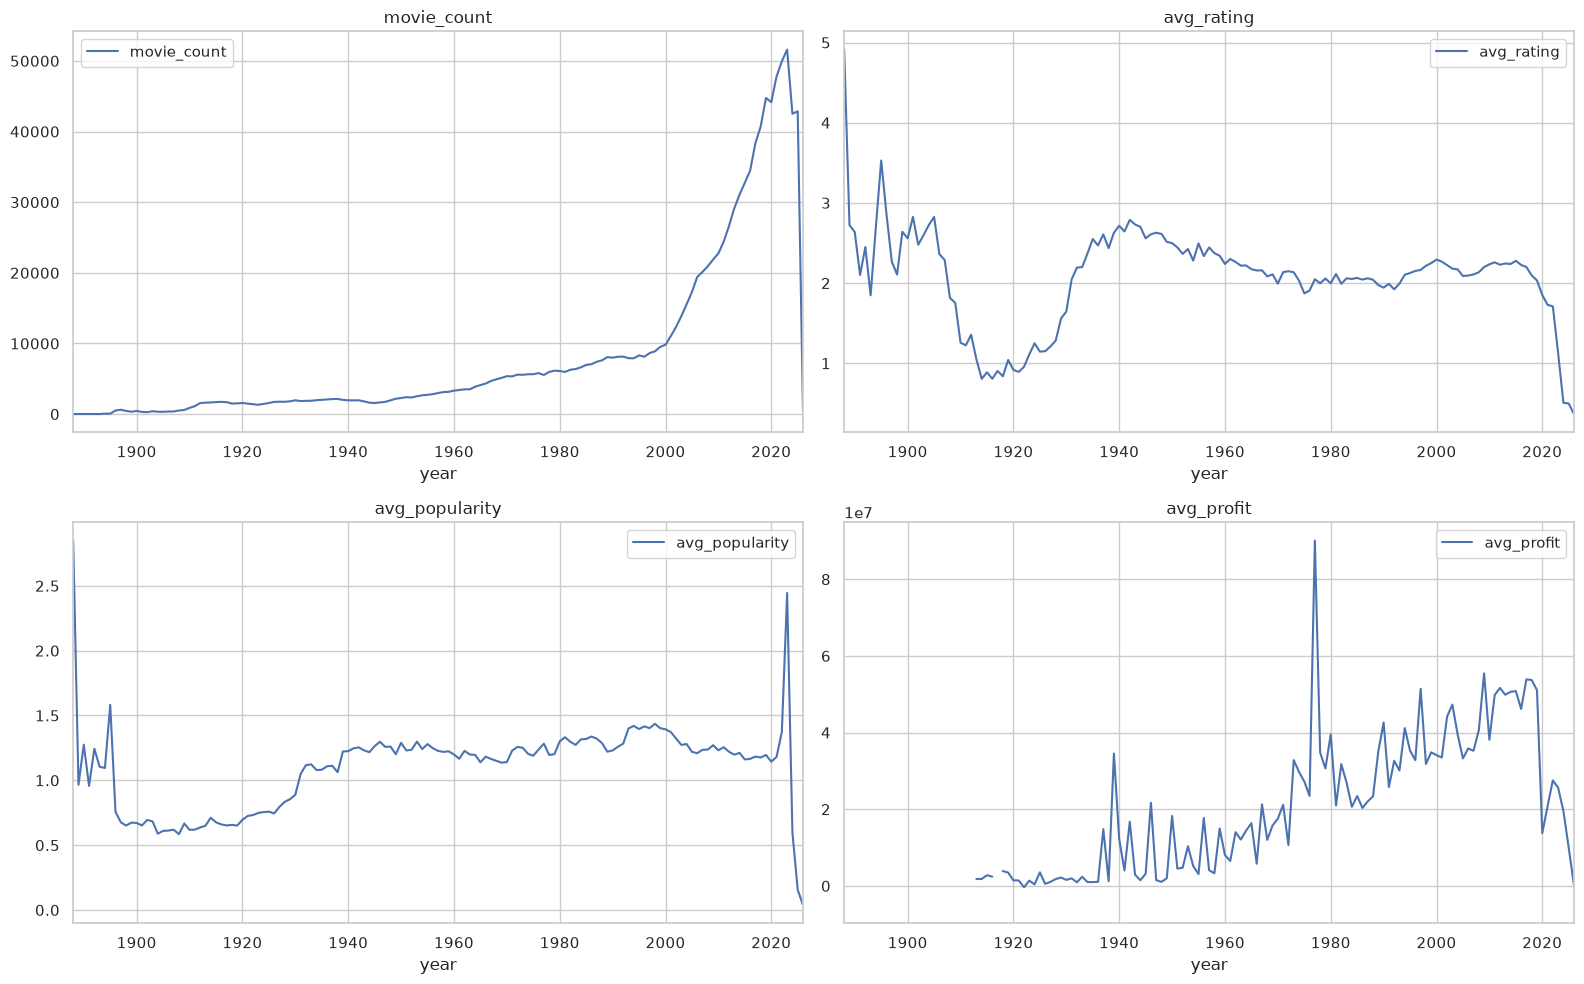

In [33]:
fig,ax=plt.subplots(2,2,figsize=(16,10))
for a,c in zip(ax.ravel(),['movie_count','avg_rating','avg_popularity','avg_profit']): yearly.plot(x='year',y=c,ax=a,title=c); a.set_xlim(yearly.year.min(),yearly.year.max())
plt.tight_layout(); plt.show()

,releases,avg_revenue,avg_rating,avg_popularity
month,,,,
1,244714,17699608.91,1.32,0.77
2,65490,30786719.85,2.14,1.30
3,77379,35353746.06,2.12,1.31
4,75929,35222270.61,2.09,1.26
5,75562,50579579.04,2.02,1.23
6,80872,58428701.44,1.99,1.25
7,66792,55010886.42,1.96,1.40
8,69848,30454953.04,2.07,1.57
9,85806,25911832.91,2.22,1.58


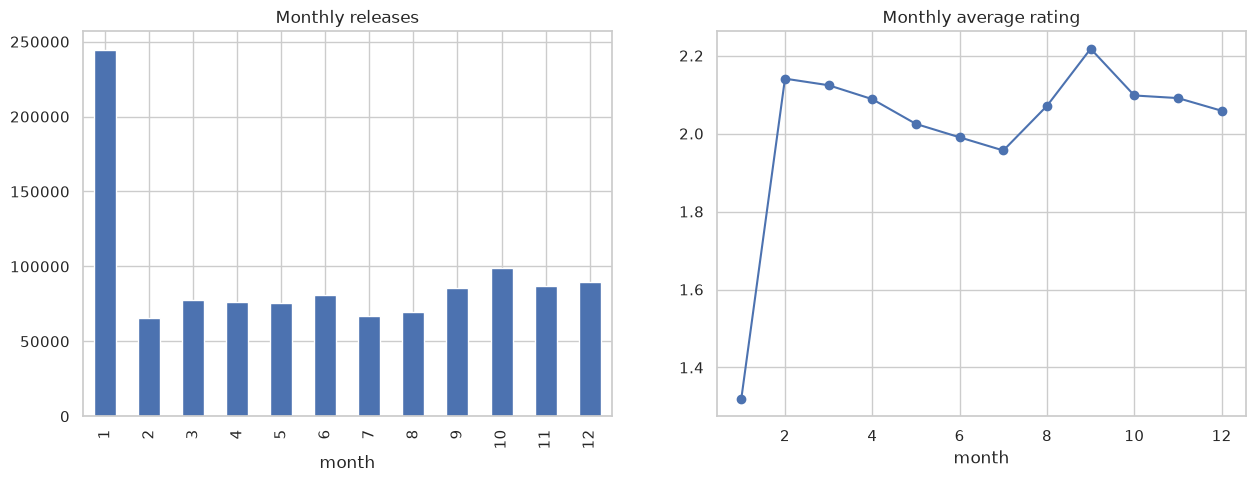

In [34]:
season=clean.groupby('month').agg(releases=('id','count'),avg_revenue=('revenue','mean'),avg_rating=('vote_average','mean'),avg_popularity=('popularity','mean')).reindex(range(1,13)); display(season.round(2))
fig,ax=plt.subplots(1,2,figsize=(15,5)); season.releases.plot.bar(ax=ax[0],title='Monthly releases'); season.avg_rating.plot.line(marker='o',ax=ax[1],title='Monthly average rating'); plt.show()

In [35]:
clean['genre_combination']=clean.genres.fillna('').map(lambda x:' + '.join(sorted(split_labels(x))) if split_labels(x) else 'Unknown')
combo=clean.groupby('genre_combination').agg(movie_count=('id','count'),avg_rating=('vote_average','mean'),avg_revenue=('revenue','mean'),avg_profit=('profit','mean'),avg_popularity=('popularity','mean')).query('movie_count>=50').sort_values('movie_count',ascending=False)
display(combo.head(20).round(2))
display(clean.groupby('original_language').agg(movie_count=('id','count'),avg_rating=('vote_average','mean'),avg_revenue=('revenue','mean'),avg_budget=('budget','mean'),avg_popularity=('popularity','mean')).query('movie_count>=100').sort_values('movie_count',ascending=False).head(20).round(2))

,movie_count,avg_rating,avg_revenue,avg_profit,avg_popularity
genre_combination,,,,,
Unknown,669415,0.59,20876182.55,17572846.04,0.39
Documentary,169287,1.50,4439617.24,4481602.30,0.67
Drama,128106,1.92,10920574.54,9076644.56,1.10
Comedy,68081,2.40,21249743.80,20993389.69,1.23
Animation,37818,1.33,2535310.02,1983656.73,0.65
Music,30671,2.06,13912583.77,9995348.71,0.65
Horror,27834,1.57,16829106.86,17686512.94,1.13
Comedy + Drama,18855,2.92,17822151.58,17683197.25,1.65
Drama + Romance,17560,2.91,20340582.07,18824662.64,2.27


,movie_count,avg_rating,avg_revenue,avg_budget,avg_popularity
original_language,,,,,
en,820431,1.42,48320596.17,4915694.15,1.01
fr,85849,1.92,15146112.22,2518996.75,0.95
es,77140,1.84,6883053.19,514642.10,0.83
ja,69148,1.26,25879842.28,5865564.66,1.25
de,65784,1.45,6107574.07,1164376.17,0.74
zh,47164,0.78,46438947.89,8505577.59,0.65
pt,46402,1.20,11023315.87,490295.66,0.57
it,29792,2.22,5798847.05,1779795.52,1.29
ru,29472,1.56,5862879.65,3599967.70,0.76


In [36]:
display(country_counts.head(20).to_frame('movie_count'))
company_counts=explode_counts(clean,'production_companies'); display(company_counts.head(20).to_frame('movie_count'))

,movie_count
production_countries,
United States of America,220477
Japan,55568
France,52467
United Kingdom,50421
Germany,48981
Canada,27793
India,24528
Brazil,22450
Italy,21556


,movie_count
production_companies,
BBC,3601
Warner Bros. Pictures,3360
Evil Angel,3289
ARTE,3026
Columbia Pictures,3000
ONF | NFB,2934
Metro-Goldwyn-Mayer,2903
Universal Pictures,2831
Paramount,2658


## 25–27 — Production Companies, Top Movies, Profitability

In [37]:
def top_table(col,n=20):
    return clean[['id','title','release_date','vote_average','vote_count','budget','revenue','profit','roi','popularity']].dropna(subset=[col]).sort_values(col,ascending=False).head(n)
for c in ['revenue','profit','roi','vote_average','popularity','vote_count']:
    print('TOP 20',c); display(top_table(c).round(3))

TOP 20 revenue


,id,title,release_date,vote_average,vote_count,budget,revenue,profit,roi,popularity
633843,1679728,Han Sur Lesses,2026-04-23,0.000,0.0,500.0,5.000000e+09,4.999999e+09,9.999999e+06,0.007
626121,1644364,In the Virtual End (Linkin Park HL2 music video),2009-11-02,0.000,0.0,1.0,5.000000e+09,5.000000e+09,5.000000e+09,0.000
772935,1492510,Juliet and Romeo - 1231 ☆*: .｡. o(≧▽≦)o .｡.:*☆...,1800-01-01,0.000,0.0,1.0,5.000000e+09,5.000000e+09,5.000000e+09,0.007
456850,1407985,babben: the movie,NaT,0.000,0.0,100.0,5.000000e+09,5.000000e+09,5.000000e+07,0.600
318397,1758426,Marvel's Spider-Man,2018-09-07,10.000,1.0,100000000.0,3.800000e+09,3.700000e+09,3.700000e+01,0.107
669548,1605334,Macbeth's Ambition,2026-01-02,0.000,0.0,10000000.0,3.477780e+09,3.467780e+09,3.467780e+02,0.021
315053,1676327,Red Dead Redemption II,NaT,9.000,1.0,540000000.0,3.100000e+09,2.560000e+09,4.741000e+00,0.000
606145,1224207,Adventures in Bora Bora,2023-08-23,0.000,0.0,800000000.0,3.000000e+09,2.200000e+09,2.750000e+00,0.000
255521,1270893,TikTok Rizz Party,2024-04-01,10.000,1.0,250000000.0,3.000000e+09,2.750000e+09,1.100000e+01,0.000
506418,1236552,Bee Movie,NaT,0.000,0.0,150000000.0,2.930000e+09,2.780000e+09,1.853300e+01,1.400


TOP 20 profit


,id,title,release_date,vote_average,vote_count,budget,revenue,profit,roi,popularity
626121,1644364,In the Virtual End (Linkin Park HL2 music video),2009-11-02,0.000,0.0,1.0,5.000000e+09,5.000000e+09,5.000000e+09,0.000
772935,1492510,Juliet and Romeo - 1231 ☆*: .｡. o(≧▽≦)o .｡.:*☆...,1800-01-01,0.000,0.0,1.0,5.000000e+09,5.000000e+09,5.000000e+09,0.007
456850,1407985,babben: the movie,NaT,0.000,0.0,100.0,5.000000e+09,5.000000e+09,5.000000e+07,0.600
633843,1679728,Han Sur Lesses,2026-04-23,0.000,0.0,500.0,5.000000e+09,4.999999e+09,9.999999e+06,0.007
318397,1758426,Marvel's Spider-Man,2018-09-07,10.000,1.0,100000000.0,3.800000e+09,3.700000e+09,3.700000e+01,0.107
669548,1605334,Macbeth's Ambition,2026-01-02,0.000,0.0,10000000.0,3.477780e+09,3.467780e+09,3.467780e+02,0.021
506418,1236552,Bee Movie,NaT,0.000,0.0,150000000.0,2.930000e+09,2.780000e+09,1.853300e+01,1.400
255521,1270893,TikTok Rizz Party,2024-04-01,10.000,1.0,250000000.0,3.000000e+09,2.750000e+09,1.100000e+01,0.000
3,19995,Avatar,2009-12-15,7.573,29815.0,237000000.0,2.923706e+09,2.686706e+09,1.133600e+01,79.932
315053,1676327,Red Dead Redemption II,NaT,9.000,1.0,540000000.0,3.100000e+09,2.560000e+09,4.741000e+00,0.000


TOP 20 roi


,id,title,release_date,vote_average,vote_count,budget,revenue,profit,roi,popularity
772935,1492510,Juliet and Romeo - 1231 ☆*: .｡. o(≧▽≦)o .｡.:*☆...,1800-01-01,0.0,0.0,1.0,5.000000e+09,5.000000e+09,5.000000e+09,0.007
626121,1644364,In the Virtual End (Linkin Park HL2 music video),2009-11-02,0.0,0.0,1.0,5.000000e+09,5.000000e+09,5.000000e+09,0.000
490289,1285909,ירידתם של המגניבים,NaT,0.0,0.0,1.0,1.000000e+09,1.000000e+09,1.000000e+09,0.000
450730,1189582,Pouring Out The Heart,2023-05-17,0.0,0.0,1.0,1.000000e+09,1.000000e+09,1.000000e+09,0.726
455639,1390996,GEESE - THE MONEY TALKS TOUR '24,NaT,0.0,0.0,1.0,1.000000e+09,1.000000e+09,1.000000e+09,0.000
656821,1618715,Mauricio la Película 3: El Atacke de los Pelig...,NaT,0.0,0.0,1.0,1.000000e+09,1.000000e+09,1.000000e+09,0.007
345975,1163324,Lil Detective,NaT,10.0,1.0,2.0,1.000000e+09,1.000000e+09,5.000000e+08,0.600
639644,1682608,Słucham 9 dni dissu na raka żeby pomóc dziecio...,NaT,0.0,0.0,1.0,2.506500e+08,2.506500e+08,2.506500e+08,0.057
759868,1710597,Begone Chucky! The Film,2026-06-08,0.0,0.0,2.0,5.000000e+08,5.000000e+08,2.500000e+08,0.000
490116,1286009,חברים על סמים 1,2023-10-02,0.0,0.0,5.0,1.000000e+09,1.000000e+09,2.000000e+08,1.090


... (2 outputs left out)

TOP 20 popularity


,id,title,release_date,vote_average,vote_count,budget,revenue,profit,roi,popularity
3868,565770,Blue Beetle,2023-08-16,7.139,1023.0,120000000.0,1.248182e+08,4.818235e+06,0.040,2994.357
5051,980489,Gran Turismo,2023-08-09,8.068,702.0,60000000.0,1.148000e+08,5.480000e+07,0.913,2680.593
51831,754720,A Female Boss with Big Tits and Her Cherry Boy...,2020-01-16,9.000,19.0,NaN,NaN,NaN,NaN,2020.286
7919,968051,The Nun II,2023-09-06,6.545,365.0,38500000.0,2.312000e+08,1.927000e+08,5.005,1692.778
2130,615656,Meg 2: The Trench,2023-08-02,6.912,2034.0,129000000.0,3.840565e+08,2.550565e+08,1.977,1567.273
9964,762430,Retribution,2023-08-23,6.816,258.0,20000000.0,1.290546e+07,-7.094536e+06,-0.355,1547.220
4016,1008042,Talk to Me,2023-07-26,7.214,973.0,4500000.0,7.260000e+07,6.810000e+07,15.133,1458.514
1110,385687,Fast X,2023-05-17,7.265,3881.0,340000000.0,7.047097e+08,3.647097e+08,1.073,1175.267
6398,678512,Sound of Freedom,2023-07-03,7.973,503.0,15000000.0,2.125872e+08,1.975872e+08,13.172,1111.036
825,346698,Barbie,2023-07-19,7.279,5074.0,145000000.0,1.428545e+09,1.283545e+09,8.852,1069.340


TOP 20 vote_count


,id,title,release_date,vote_average,vote_count,budget,revenue,profit,roi,popularity
0,27205,Inception,2010-07-15,8.364,34495.0,160000000.0,8.255328e+08,6.655328e+08,4.160,83.952
1,157336,Interstellar,2014-11-05,8.417,32571.0,165000000.0,7.017292e+08,5.367292e+08,3.253,140.241
2,155,The Dark Knight,2008-07-16,8.512,30619.0,185000000.0,1.004558e+09,8.195584e+08,4.430,130.643
3,19995,Avatar,2009-12-15,7.573,29815.0,237000000.0,2.923706e+09,2.686706e+09,11.336,79.932
4,24428,The Avengers,2012-04-25,7.710,29166.0,220000000.0,1.518816e+09,1.298816e+09,5.904,98.082
5,293660,Deadpool,2016-02-09,7.606,28894.0,58000000.0,7.831000e+08,7.251000e+08,12.502,72.735
6,299536,Avengers: Infinity War,2018-04-25,8.255,27713.0,300000000.0,2.052415e+09,1.752415e+09,5.841,154.340
7,550,Fight Club,1999-10-15,8.438,27238.0,63000000.0,1.008538e+08,3.785375e+07,0.601,69.498
8,118340,Guardians of the Galaxy,2014-07-30,7.906,26638.0,170000000.0,7.727766e+08,6.027766e+08,3.546,33.255
9,680,Pulp Fiction,1994-09-10,8.488,25893.0,8500000.0,2.139000e+08,2.054000e+08,24.165,74.862


In [38]:
# Bayesian/weighted rating avoids ranking tiny vote counts above well-supported films
C=clean.vote_average.mean(); m=clean.vote_count.quantile(.90)
clean['weighted_rating']=(clean.vote_count/(clean.vote_count+m))*clean.vote_average+(m/(clean.vote_count+m))*C
display(clean[['title','vote_average','vote_count','weighted_rating']].sort_values('weighted_rating',ascending=False).head(20).round(3))

,title,vote_average,vote_count,weighted_rating
27875,What's New Scooby-Doo? Vol. 3: Halloween Boos ...,9.980,50.0,9.499
29235,What's New Scooby-Doo? Vol. 4: Merry Scary Hol...,10.000,46.0,9.479
29141,"What's New, Scooby-Doo? Vol. 7: Ready to Scare",10.000,46.0,9.479
32024,The 1st 13th Annual Fancy Anvil Awards Show Pr...,10.000,40.0,9.406
28410,"What's New, Scooby-Doo? Vol. 5: Sports Spookta...",9.900,48.0,9.405
28405,"What's New, Scooby-Doo? Vol. 1: Space Ape at t...",9.900,48.0,9.405
28855,"What's New, Scooby-Doo? Vol. 7: Ghosts on the Go!",9.872,47.0,9.369
30413,Scooby-Doo: Mystery in Motion,9.900,43.0,9.351
25867,Scooby-Doo! and the Werewolves,9.763,57.0,9.349
31466,Cartoon Network Christmas: Yuletide Follies,9.900,41.0,9.327


,count,mean,std,min,1%,25%,50%,75%,90%,99%,max
profit,18325.0,31250912.30,1.520068e+08,-899999984.0,-39421694.84,-100.0,119.0,7308964.00,70496312.6,6.651064e+08,5.000000e+09
roi,18325.0,931319.16,5.457361e+07,-1.0,-1.00,-0.3,0.4,2.69,9.0,3.151000e+03,5.000000e+09


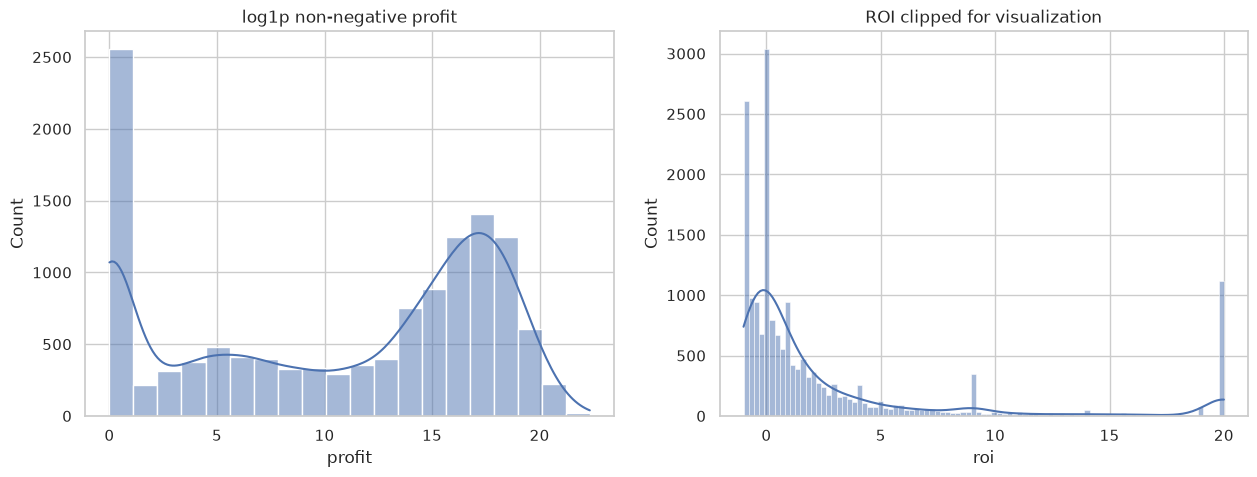

In [39]:
prof=clean[['profit','roi']].describe(percentiles=[.01,.25,.5,.75,.9,.99]).T; display(prof.round(2))
fig,ax=plt.subplots(1,2,figsize=(15,5)); sns.histplot(np.log1p(clean.loc[clean.profit>=0,'profit'].dropna()),kde=True,ax=ax[0]); ax[0].set_title('log1p non-negative profit'); sns.histplot(clean.roi.dropna().clip(-1,20),kde=True,ax=ax[1]); ax[1].set_title('ROI clipped for visualization'); plt.show()

## 28–30 — Text Analytics and TF-IDF

In [40]:
text_summary=pd.DataFrame({'overview_missing_pct':[clean.overview.isna().mean()*100],'tagline_missing_pct':[clean.tagline.isna().mean()*100],'overview_mean_words':[clean.overview_word_count.mean()],'overview_median_words':[clean.overview_word_count.median()],'tagline_mean_words':[clean.tagline_word_count.mean()]}); display(text_summary.round(2))
text_cols=['overview_length','overview_word_count','tagline_length','tagline_word_count']; display(clean[text_cols].describe().round(2))

,overview_missing_pct,tagline_missing_pct,overview_mean_words,overview_median_words,tagline_mean_words
0,23.24,86.0,34.37,25.0,1.12


,overview_length,overview_word_count,tagline_length,tagline_word_count
count,1493757.0,1493757.00,1493757.0,1493757.00
mean,202.9,34.37,6.26,1.12
std,213.64,36.11,20.14,3.55
min,0.0,0.00,0.0,0.00
25%,20.0,3.00,0.0,0.00
50%,145.0,25.00,0.0,0.00
75%,304.0,52.00,0.0,0.00
max,1000.0,231.00,256.0,58.00


,word,count
0,she,44204
1,they,42660
2,life,31661
3,him,31081
4,young,27040
5,after,26251
6,film,24964
7,out,24358
8,man,22309
9,love,22297


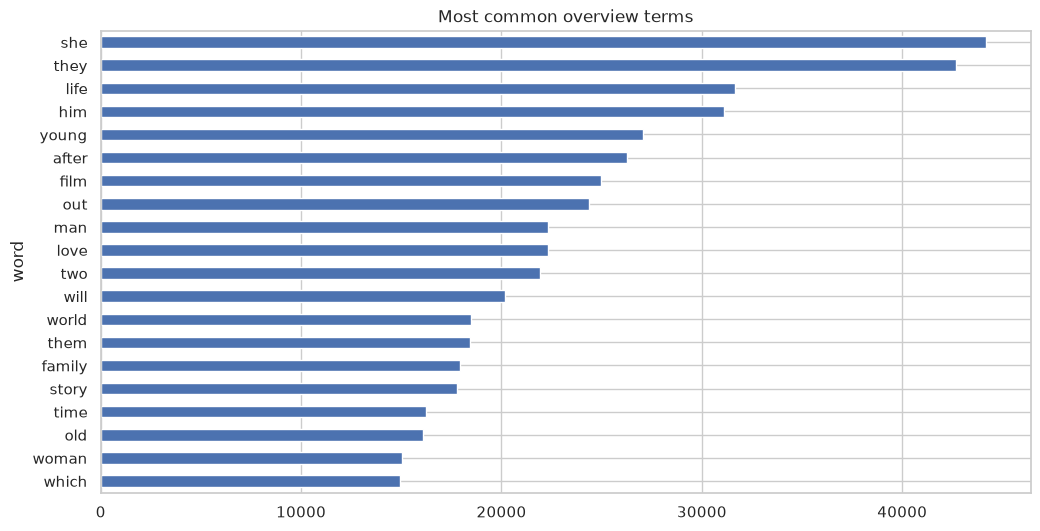

In [41]:
from collections import Counter
def word_counter(series):
    words=[]
    for s in series.dropna().astype(str).head(200000): words += re.findall(r"[A-Za-z']{3,}",s.lower())
    stop=set('the and for with that this from are was his her has its into their about have not but who had one all also can more when new'.split())
    return Counter(w for w in words if w not in stop)
common=word_counter(clean.overview); display(pd.DataFrame(common.most_common(30),columns=['word','count']))
fig,ax=plt.subplots(figsize=(12,6)); pd.DataFrame(common.most_common(20),columns=['word','count']).sort_values('count').plot.barh(x='word',y='count',legend=False,ax=ax); ax.set_title('Most common overview terms'); plt.show()

In [42]:
# Bounded TF-IDF sample: enough for analysis without allocating a million-document sparse matrix
text_sample=clean.loc[clean.overview.fillna('').str.len()>20,['overview','vote_average','vote_count']].sample(min(100000, (clean.overview.fillna('').str.len()>20).sum()),random_state=RANDOM_STATE)
vectorizer=TfidfVectorizer(stop_words='english',max_features=1500,min_df=5,max_df=.95,ngram_range=(1,2))
X_text=vectorizer.fit_transform(text_sample.overview.fillna('')); print('TF-IDF shape:',X_text.shape,'sparse density:',X_text.nnz/(X_text.shape[0]*X_text.shape[1]))
terms=np.array(vectorizer.get_feature_names_out()); mean_tfidf=np.asarray(X_text.mean(axis=0)).ravel(); display(pd.DataFrame({'term':terms,'mean_tfidf':mean_tfidf}).sort_values('mean_tfidf',ascending=False).head(25))

TF-IDF shape: (100000, 1500) sparse density: 0.00785854


,term,mean_tfidf
491,film,0.030581
774,life,0.019921
1494,young,0.017434
824,man,0.017156
805,love,0.014533
1268,story,0.014315
920,new,0.014263
1479,world,0.014225
1192,short,0.013893
359,documentary,0.013186


Explained variance: [0.00440322 0.00958774] cumulative: 0.013990956818502308


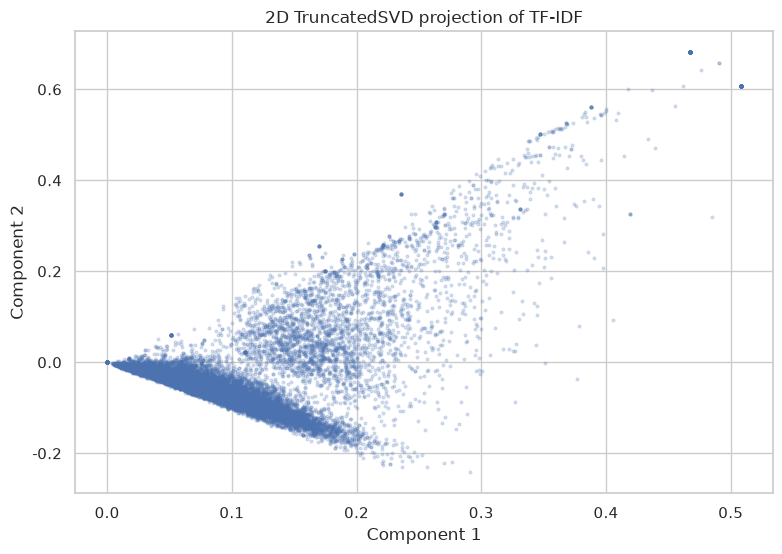

In [43]:
svd=TruncatedSVD(n_components=2,random_state=RANDOM_STATE); coords=svd.fit_transform(X_text[:20000]); print('Explained variance:',svd.explained_variance_ratio_, 'cumulative:',svd.explained_variance_ratio_.sum())
plt.figure(figsize=(9,6)); plt.scatter(coords[:,0],coords[:,1],s=4,alpha=.2); plt.title('2D TruncatedSVD projection of TF-IDF'); plt.xlabel('Component 1'); plt.ylabel('Component 2'); plt.show()

## 31–40 — Feature Engineering, Encoding, Scaling, Selection, VIF

In [44]:
feature_summary=pd.DataFrame({'feature':['profit','roi','movie_age','release_year','release_month','release_quarter','genre_count','overview_length','overview_word_count','tagline_length','tagline_word_count','keyword_count','language_count','country_count','production_company_count'], 'created':[c in clean.columns for c in ['profit','roi','movie_age','year','month','quarter','genre_count','overview_length','overview_word_count','tagline_length','tagline_word_count','keywords_count','spoken_languages_count','production_countries_count','production_companies_count']], 'meaning':['revenue-budget','profit/budget','years since release','calendar year','month','quarter','number of genres','characters','words','characters','words','keywords','spoken languages','countries','companies']}); display(feature_summary)

,feature,created,meaning
0,profit,True,revenue-budget
1,roi,True,profit/budget
2,movie_age,True,years since release
3,release_year,True,calendar year
4,release_month,True,month
5,release_quarter,True,quarter
6,genre_count,True,number of genres
7,overview_length,True,characters
8,overview_word_count,True,words
9,tagline_length,True,characters


In [45]:
# Ratios with explicit zero/missing protection
clean['revenue_per_budget']=clean.revenue/clean.budget
clean['budget_per_runtime']=clean.budget/clean.runtime
clean['revenue_per_runtime']=clean.revenue/clean.runtime
clean['votes_per_popularity']=clean.vote_count/clean.popularity.replace(0,np.nan)
for c in ['revenue_per_budget','budget_per_runtime','revenue_per_runtime','votes_per_popularity']:
    clean.loc[~np.isfinite(clean[c]),c]=np.nan
print(clean[['revenue_per_budget','budget_per_runtime','revenue_per_runtime','votes_per_popularity']].describe(percentiles=[.5,.9,.99]).round(2))

       revenue_per_budget  budget_per_runtime  revenue_per_runtime  \
count        1.832500e+04        6.854300e+04         2.169900e+04   
mean         9.313202e+05        5.956906e+04         7.747627e+05   
std          5.457361e+07        1.295525e+06         1.648641e+07   
min          0.000000e+00        0.000000e+00         0.000000e+00   
50%          1.400000e+00        2.176500e+02         1.520312e+04   
90%          1.000000e+01        7.777778e+04         8.243252e+05   
99%          3.152000e+03        8.796308e+05         6.072226e+06   
max          5.000000e+09        2.285380e+08         1.250000e+09   

       votes_per_popularity  
count            1220964.00  
mean                   1.90  
std                   21.28  
min                    0.00  
50%                    0.00  
90%                    4.24  
99%                   21.86  
max                 8392.16  


In [46]:
# Quantile bins are descriptive, not arbitrary labels; ranking handles tied popularity values
clean['budget_category']=pd.qcut(clean.budget,q=4,labels=['Low','Medium','High','Very High'],duplicates='drop')
clean['runtime_category']=pd.cut(clean.runtime,bins=[-np.inf,90,120,np.inf],labels=['Short','Medium','Long'])
clean['popularity_category']=pd.qcut(clean.popularity.rank(method='first'),q=3,labels=['Low','Medium','High'])
display(clean[['budget_category','runtime_category','popularity_category']].apply(lambda s:s.value_counts(dropna=False)))

,budget_category,runtime_category,popularity_category
High,22076.0,NaN,497919.0
Long,NaN,101149.0,NaN
Low,22167.0,NaN,497919.0
Medium,22061.0,184867.0,497919.0
Short,NaN,735417.0,NaN
Very High,21453.0,NaN,NaN
NaN,1406000.0,472324.0,NaN


In [47]:
# One-hot encoding is appropriate for nominal genres; no ordinal labels are imposed
genre_lists=clean[['id','genres']].copy(); genre_lists['genre_list']=genre_lists['genres'].map(lambda x:split_labels(x))
genre_long_for_encoding=genre_lists[['id','genre_list']].explode('genre_list').dropna(subset=['genre_list']).reset_index(drop=True)
genre_dummies=pd.crosstab(genre_long_for_encoding['id'].to_numpy(),genre_long_for_encoding['genre_list'].to_numpy()).gt(0).astype('int8').add_prefix('genre_')
print('Genre one-hot matrix:',genre_dummies.shape)

Genre one-hot matrix: (824342, 19)


In [48]:
# VIF on a bounded complete sample, excluding direct target-derived columns
vif_cols=['vote_count','popularity','runtime','vote_average','genre_count','overview_word_count','movie_age']
vif_data=clean[vif_cols].replace([np.inf,-np.inf],np.nan).dropna().sample(min(20000,clean[vif_cols].replace([np.inf,-np.inf],np.nan).dropna().shape[0]),random_state=RANDOM_STATE)
vif_out=pd.DataFrame({'feature':vif_cols,'VIF':[variance_inflation_factor(vif_data.values,i) for i in range(len(vif_cols))]}); display(vif_out.round(2))

,feature,VIF
0,vote_count,1.13
1,popularity,1.19
2,runtime,1.07
3,vote_average,1.18
4,genre_count,1.13
5,overview_word_count,1.04
6,movie_age,1.02


### Feature selection logic
نستبعد `revenue`, `profit`, و`roi` من نموذج النجاح عندما يكون تعريف النجاح مبنيًا على التقييم/الأداء المستقبلي؛ كما نستبعد المعرفات والمسارات. نستخدم variance/association كمرشحات، ثم أهمية النموذج، مع الانتباه إلى أن الأهمية لا تعني السببية.

## 41–43 — Target, Leakage Prevention, Train/Test Split

In [49]:
# Scientifically explicit target: high-rated movie among adequately voted movies
model_base=clean[(clean.vote_count>=rating_support_threshold)&clean.vote_average.notna()].copy()
model_base['success']=(model_base.vote_average>=7.0).astype(int)
print('Model base:',model_base.shape); print(model_base.success.value_counts(normalize=True).rename('proportion'))
feature_cols=['popularity','vote_count','runtime','genre_count','overview_word_count','tagline_word_count','year','month','original_language','status','adult']
model_base=model_base.dropna(subset=['success'])
X=model_base[feature_cols].copy(); y=model_base.success
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=RANDOM_STATE)
print('Train:',X_train.shape,'Test:',X_test.shape,'train rate:',y_train.mean(),'test rate:',y_test.mean())

Model base: (27981, 58)
success
0    0.734641
1    0.265359
Name: proportion, dtype: float64
Train: (22384, 11) Test: (5597, 11) train rate: 0.26536812008577554 test rate: 0.26532070752188675


In [50]:
display(pd.DataFrame({'Feature':feature_cols,'Used':True,'Leakage risk':['low','low','low','low','low','low','medium: engagement proxy','medium: historical availability','low','low','low']}))
print('Excluded: revenue, budget, profit, roi, weighted_rating, title, IDs, URLs, poster paths and raw free text for tabular models.')

,Feature,Used,Leakage risk
0,popularity,True,low
1,vote_count,True,low
2,runtime,True,low
3,genre_count,True,low
4,overview_word_count,True,low
5,tagline_word_count,True,low
6,year,True,medium: engagement proxy
7,month,True,medium: historical availability
8,original_language,True,low
9,status,True,low


Excluded: revenue, budget, profit, roi, weighted_rating, title, IDs, URLs, poster paths and raw free text for tabular models.


## 44–50 — Baseline and Classification Models

In [51]:
num_cols=['popularity','vote_count','runtime','genre_count','overview_word_count','tagline_word_count','year','month']; cat_cols=['original_language','status','adult']
pre=ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',RobustScaler())]),num_cols),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat_cols)])
models={'Dummy':DummyClassifier(strategy='prior',random_state=RANDOM_STATE),'Logistic Regression':LogisticRegression(max_iter=1000,class_weight='balanced',random_state=RANDOM_STATE),'Decision Tree':DecisionTreeClassifier(max_depth=8,min_samples_leaf=20,class_weight='balanced',random_state=RANDOM_STATE),'Random Forest':RandomForestClassifier(n_estimators=160,max_depth=14,min_samples_leaf=5,n_jobs=-1,class_weight='balanced_subsample',random_state=RANDOM_STATE)}
results=[]; fitted={}
for name,model in models.items():
    pipe=Pipeline([('preprocess',pre),('model',model)]); pipe.fit(X_train,y_train); pred=pipe.predict(X_test); prob=pipe.predict_proba(X_test)[:,1] if hasattr(pipe,'predict_proba') else None
    results.append([name,accuracy_score(y_test,pred),precision_score(y_test,pred,zero_division=0),recall_score(y_test,pred,zero_division=0),f1_score(y_test,pred,zero_division=0),roc_auc_score(y_test,prob) if prob is not None else np.nan]); fitted[name]=pipe
model_results=pd.DataFrame(results,columns=['Model','Accuracy','Precision','Recall','F1','ROC-AUC']).set_index('Model'); display(model_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Dummy,0.7347,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.7031,0.4549,0.6007,0.5177,0.6955
Decision Tree,0.7234,0.4842,0.6498,0.5549,0.7692
Random Forest,0.7626,0.5436,0.6552,0.5942,0.7996


Best by F1: Random Forest
              precision    recall  f1-score   support

           0       0.87      0.80      0.83      4112
           1       0.54      0.66      0.59      1485

    accuracy                           0.76      5597
   macro avg       0.70      0.73      0.71      5597
weighted avg       0.78      0.76      0.77      5597



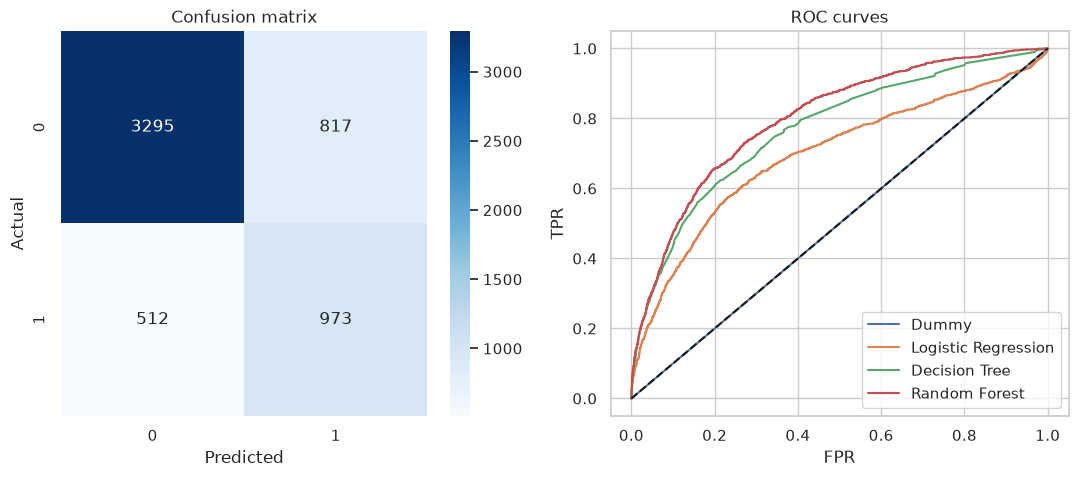

In [52]:
best_name=model_results['F1'].idxmax(); best=fitted[best_name]; print('Best by F1:',best_name); print(classification_report(y_test,best.predict(X_test),zero_division=0))
fig,ax=plt.subplots(1,2,figsize=(13,5)); sns.heatmap(confusion_matrix(y_test,best.predict(X_test)),annot=True,fmt='d',cmap='Blues',ax=ax[0]); ax[0].set_title('Confusion matrix'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
for name,pipe in fitted.items():
    if hasattr(pipe,'predict_proba'):
        fpr,tpr,_=roc_curve(y_test,pipe.predict_proba(X_test)[:,1]); ax[1].plot(fpr,tpr,label=name)
ax[1].plot([0,1],[0,1],'k--'); ax[1].legend(); ax[1].set_title('ROC curves'); ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR'); plt.show()

In [53]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE); cv_pipe=fitted['Random Forest']; cv_scores=cross_validate(cv_pipe,X,y,cv=cv,scoring=['accuracy','f1','roc_auc'],n_jobs=-1); cv_table=pd.DataFrame({m.replace('test_',''):v for m,v in cv_scores.items() if m.startswith('test_')}); display(pd.DataFrame({'mean':cv_table.mean(),'std':cv_table.std()}).round(4))

,mean,std
accuracy,0.7529,0.0054
f1,0.5840,0.0063
roc_auc,0.7973,0.0048


In [54]:
param_grid={'model__n_estimators':[100,180],'model__max_depth':[10,16,None],'model__min_samples_leaf':[2,5]}
search=GridSearchCV(Pipeline([('preprocess',pre),('model',RandomForestClassifier(class_weight='balanced_subsample',n_jobs=-1,random_state=RANDOM_STATE))]),param_grid,scoring='f1',cv=3,n_jobs=-1); search.fit(X_train,y_train); tuned_pred=search.predict(X_test); tuned_prob=search.predict_proba(X_test)[:,1]
print('Best params:',search.best_params_); print('Before RF F1:',model_results.loc['Random Forest','F1'],'After tuning F1:',f1_score(y_test,tuned_pred)); print('After tuning ROC-AUC:',roc_auc_score(y_test,tuned_prob))

Best params: {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 180}
Before RF F1: 0.5941984732824428 After tuning F1: 0.5867587072481958
After tuning ROC-AUC: 0.8026670728032597


,feature,importance_mean,importance_std
8,original_language,0.118671,0.001106
1,vote_count,0.078774,0.006257
2,runtime,0.077224,0.000351
6,year,0.070281,0.002330
0,popularity,0.007926,0.002167
3,genre_count,0.005086,0.002749
7,month,0.002926,0.001630
4,overview_word_count,0.001977,0.001102
5,tagline_word_count,0.001223,0.001338
9,status,0.000000,0.000000


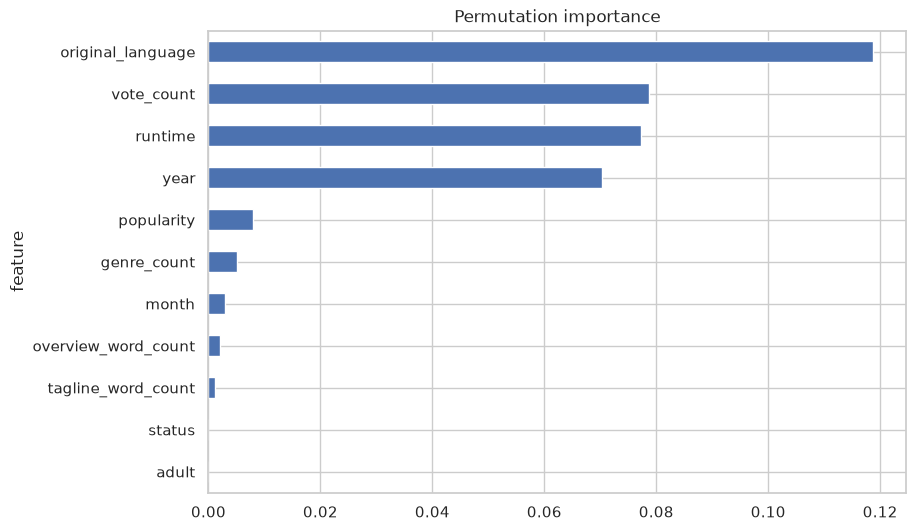

In [55]:
# Permutation importance is model-agnostic and interpretable at raw feature level
perm=permutation_importance(search.best_estimator_,X_test,y_test,n_repeats=3,random_state=RANDOM_STATE,scoring='f1',n_jobs=-1); imp=pd.DataFrame({'feature':X_test.columns,'importance_mean':perm.importances_mean,'importance_std':perm.importances_std}).sort_values('importance_mean',ascending=False); display(imp)
imp.sort_values('importance_mean').plot.barh(x='feature',y='importance_mean',legend=False,figsize=(9,6),title='Permutation importance'); plt.show()

In [56]:
err=X_test.copy(); err['actual']=y_test; err['predicted']=tuned_pred; err['probability']=tuned_prob; err['error_type']=np.select([(err.actual==0)&(err.predicted==1),(err.actual==1)&(err.predicted==0)],['False Positive','False Negative'],'Correct'); display(err[err.error_type!='Correct'].head(20))

,popularity,vote_count,runtime,genre_count,overview_word_count,tagline_word_count,year,month,original_language,status,adult,actual,predicted,probability,error_type
4188,12.270,920.0,116.0,3,21,0,2017.0,9.0,no,Released,False,0,1,0.688113,False Positive
18687,11.242,95.0,103.0,2,53,5,2008.0,9.0,sv,Released,False,0,1,0.500485,False Positive
4894,8.260,738.0,7.0,2,94,11,2012.0,2.0,en,Released,False,1,0,0.463101,False Negative
5994,12.112,554.0,96.0,2,51,0,1979.0,1.0,fr,Released,False,0,1,0.575130,False Positive
9225,11.163,287.0,159.0,3,74,0,2007.0,6.0,ru,Released,False,0,1,0.697160,False Positive
26956,7.889,53.0,109.0,2,93,9,1972.0,3.0,it,Released,False,0,1,0.509385,False Positive
5877,18.037,569.0,110.0,1,24,20,1992.0,9.0,en,Released,False,1,0,0.426976,False Negative
1738,45.446,2583.0,106.0,4,60,2,2020.0,10.0,en,Released,False,0,1,0.545776,False Positive
25958,4.210,56.0,85.0,1,73,4,2011.0,6.0,en,Released,False,1,0,0.306840,False Negative
2380,22.902,1803.0,155.0,3,108,6,1993.0,6.0,en,Released,False,0,1,0.625040,False Positive


## تدريب النماذج والنتائج التفصيلية — Model Training & Results

هذا القسم يوضح التدريب فعليًا وليس مجرد تعريف للنماذج. لكل نموذج نعرض زمن التدريب، مقاييس الاختبار، مصفوفة الالتباس، ومنحنيات ROC وPrecision–Recall. كما نحتفظ بالنتائج في جداول قابلة للتصدير.

In [57]:
# Detailed per-model training report
from time import perf_counter
training_rows=[]; trained_models={}
for name,model in models.items():
    t0=perf_counter(); pipe=Pipeline([('preprocess',pre),('model',model)]); pipe.fit(X_train,y_train); elapsed=perf_counter()-t0
    pred=pipe.predict(X_test); prob=pipe.predict_proba(X_test)[:,1] if hasattr(pipe,'predict_proba') else None
    training_rows.append({'Model':name,'Train rows':len(X_train),'Test rows':len(X_test),'Training seconds':elapsed,'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred,zero_division=0),'F1':f1_score(y_test,pred,zero_division=0),'ROC-AUC':roc_auc_score(y_test,prob) if prob is not None else np.nan,'Average Precision':average_precision_score(y_test,prob) if prob is not None else np.nan})
    trained_models[name]=pipe
detailed_results=pd.DataFrame(training_rows).set_index('Model').sort_values('F1',ascending=False)
display(detailed_results.round(4))

,Train rows,Test rows,Training seconds,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Model,,,,,,,,,
Random Forest,22384,5597,1.2894,0.7626,0.5436,0.6552,0.5942,0.7996,0.6114
Decision Tree,22384,5597,0.2035,0.7234,0.4842,0.6498,0.5549,0.7692,0.5782
Logistic Regression,22384,5597,0.4817,0.7031,0.4549,0.6007,0.5177,0.6955,0.5063
Dummy,22384,5597,0.0562,0.7347,0.0000,0.0000,0.0000,0.5000,0.2653


In [58]:
# Classification report for every trained model
report_rows=[]
for name,pipe in trained_models.items():
    pred=pipe.predict(X_test); rep=classification_report(y_test,pred,output_dict=True,zero_division=0)
    report_rows.append({'Model':name,'Negative precision':rep['0']['precision'],'Negative recall':rep['0']['recall'],'Positive precision':rep['1']['precision'],'Positive recall':rep['1']['recall'],'Macro F1':rep['macro avg']['f1-score'],'Weighted F1':rep['weighted avg']['f1-score']})
class_reports=pd.DataFrame(report_rows).set_index('Model'); display(class_reports.round(4))

,Negative precision,Negative recall,Positive precision,Positive recall,Macro F1,Weighted F1
Model,,,,,,
Dummy,0.7347,1.0000,0.0000,0.0000,0.4235,0.6223
Logistic Regression,0.8369,0.7400,0.4549,0.6007,0.6516,0.7144
Decision Tree,0.8557,0.7500,0.4842,0.6498,0.6771,0.7345
Random Forest,0.8655,0.8013,0.5436,0.6552,0.7132,0.7690


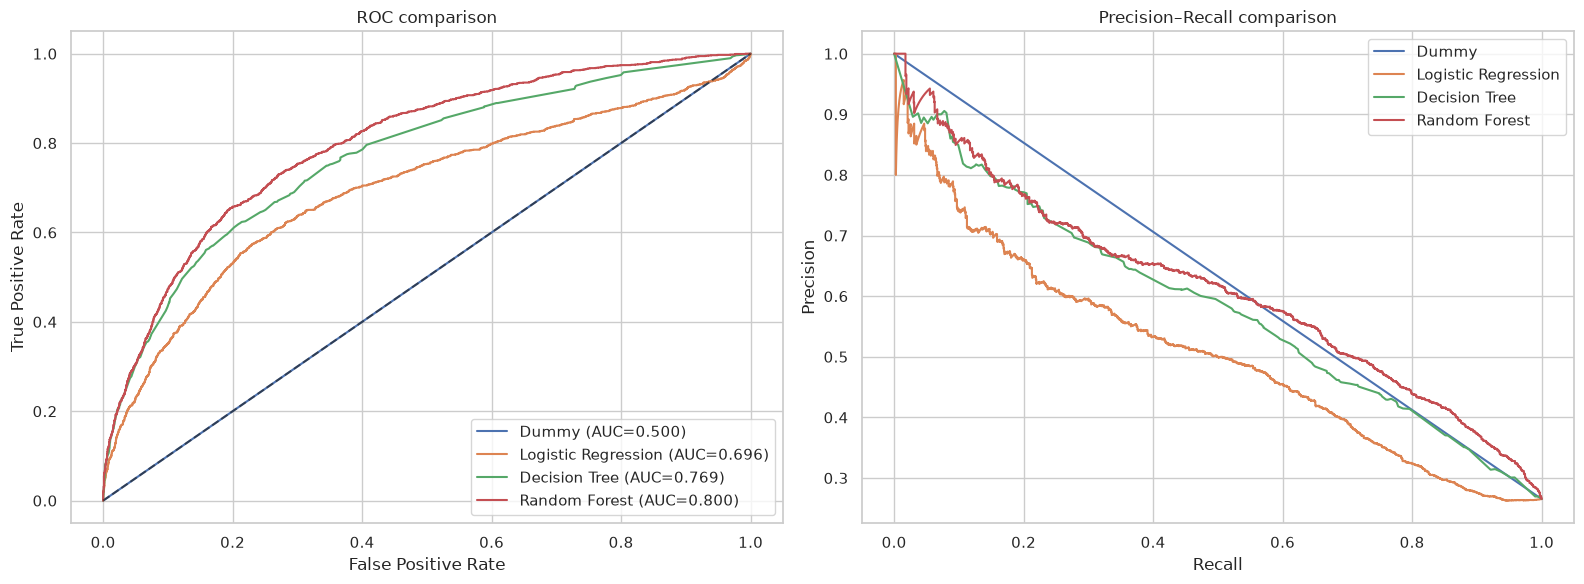

In [59]:
# ROC and Precision–Recall curves for all probabilistic models
fig,ax=plt.subplots(1,2,figsize=(16,6))
for name,pipe in trained_models.items():
    if hasattr(pipe,'predict_proba'):
        prob=pipe.predict_proba(X_test)[:,1]; fpr,tpr,_=roc_curve(y_test,prob); precision,recall,_=precision_recall_curve(y_test,prob)
        ax[0].plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(y_test,prob):.3f})'); ax[1].plot(recall,precision,label=name)
ax[0].plot([0,1],[0,1],'k--',alpha=.6); ax[0].set_title('ROC comparison'); ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate'); ax[1].set_title('Precision–Recall comparison'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

In [60]:
# Train the final tuned model and compare before/after tuning
tuned_model=search.best_estimator_; tuned_pred=tuned_model.predict(X_test); tuned_prob=tuned_model.predict_proba(X_test)[:,1]
tuning_comparison=pd.DataFrame({'Metric':['Accuracy','Precision','Recall','F1','ROC-AUC','Average Precision'],'Random Forest before tuning':[model_results.loc['Random Forest','Accuracy'],model_results.loc['Random Forest','Precision'],model_results.loc['Random Forest','Recall'],model_results.loc['Random Forest','F1'],model_results.loc['Random Forest','ROC-AUC'],average_precision_score(y_test,fitted['Random Forest'].predict_proba(X_test)[:,1])],'Random Forest after tuning':[accuracy_score(y_test,tuned_pred),precision_score(y_test,tuned_pred,zero_division=0),recall_score(y_test,tuned_pred,zero_division=0),f1_score(y_test,tuned_pred,zero_division=0),roc_auc_score(y_test,tuned_prob),average_precision_score(y_test,tuned_prob)]})
display(tuning_comparison.round(4))

,Metric,Random Forest before tuning,Random Forest after tuning
0,Accuracy,0.7626,0.7647
1,Precision,0.5436,0.5494
2,Recall,0.6552,0.6296
3,F1,0.5942,0.5868
4,ROC-AUC,0.7996,0.8027
5,Average Precision,0.6114,0.6167


In [61]:
# Persist reproducible results and the final estimator
import joblib
RESULTS_DIR=ROOT/'results'; RESULTS_DIR.mkdir(exist_ok=True)
detailed_results.to_csv(RESULTS_DIR/'model_metrics_detailed.csv'); class_reports.to_csv(RESULTS_DIR/'classification_reports.csv'); tuning_comparison.to_csv(RESULTS_DIR/'tuning_comparison.csv',index=False); joblib.dump(tuned_model,RESULTS_DIR/'final_tuned_random_forest.joblib')
print('Saved model outputs:', sorted(p.name for p in RESULTS_DIR.iterdir()))

Saved model outputs: ['classification_reports.csv', 'final_tuned_random_forest.joblib', 'model_metrics_detailed.csv', 'tuning_comparison.csv']


## 52 — Text Model and Tabular + Text Comparison

In [62]:
# Text-only target aligned to the same sample; split before fitting TF-IDF to avoid vocabulary leakage
tm=model_base[['overview','success']].copy(); tm['overview']=tm.overview.fillna('')
tm_train,tm_test=train_test_split(tm,test_size=.2,stratify=tm.success,random_state=RANDOM_STATE)
tfidf_model=Pipeline([('tfidf',TfidfVectorizer(stop_words='english',max_features=3000,min_df=5,max_df=.95)),('lr',LogisticRegression(max_iter=1000,class_weight='balanced',random_state=RANDOM_STATE))]); tfidf_model.fit(tm_train.overview,tm_train.success); tp=tfidf_model.predict(tm_test.overview); tprob=tfidf_model.predict_proba(tm_test.overview)[:,1]
text_metrics={'Text Only':[accuracy_score(tm_test.success,tp),precision_score(tm_test.success,tp,zero_division=0),recall_score(tm_test.success,tp,zero_division=0),f1_score(tm_test.success,tp,zero_division=0),roc_auc_score(tm_test.success,tprob)]}; display(pd.DataFrame(text_metrics,index=['Accuracy','Precision','Recall','F1','ROC-AUC']).T.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Text Only,0.6234,0.36,0.5394,0.4318,0.6401


In [63]:
# Compare tabular and text results on the same metrics
comparison=model_results.loc[['Logistic Regression','Random Forest'],['Accuracy','Precision','Recall','F1','ROC-AUC']].copy(); comparison.loc['Text Only']=[accuracy_score(tm_test.success,tp),precision_score(tm_test.success,tp,zero_division=0),recall_score(tm_test.success,tp,zero_division=0),f1_score(tm_test.success,tp,zero_division=0),roc_auc_score(tm_test.success,tprob)]; display(comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.7031,0.4549,0.6007,0.5177,0.6955
Random Forest,0.7626,0.5436,0.6552,0.5942,0.7996
Text Only,0.6234,0.3600,0.5394,0.4318,0.6401


## 53 — Multimodal Extension

لا يتوفر في ملف البيانات نفسه محتوى الصور، بل مسارات Poster/Backdrop فقط. لذلك لا ندّعي تنفيذ Image Embeddings أو مقارنة Tabular+Text+Image. تنفيذ ذلك يتطلب تنزيل صور خارجية وعينة محدودة، ونوثقه كعمل مستقبلي بدل اختلاق نتائج.

In [64]:
image_availability=pd.DataFrame({'asset':['poster_path','backdrop_path'],'non_missing_count':[clean.poster_path.notna().sum(),clean.backdrop_path.notna().sum()],'usable_local_images':[False,False]}); display(image_availability)

,asset,non_missing_count,usable_local_images
0,poster_path,949856,False
1,backdrop_path,364460,False


## 54–55 — Visualization Gallery and Analytical Tables

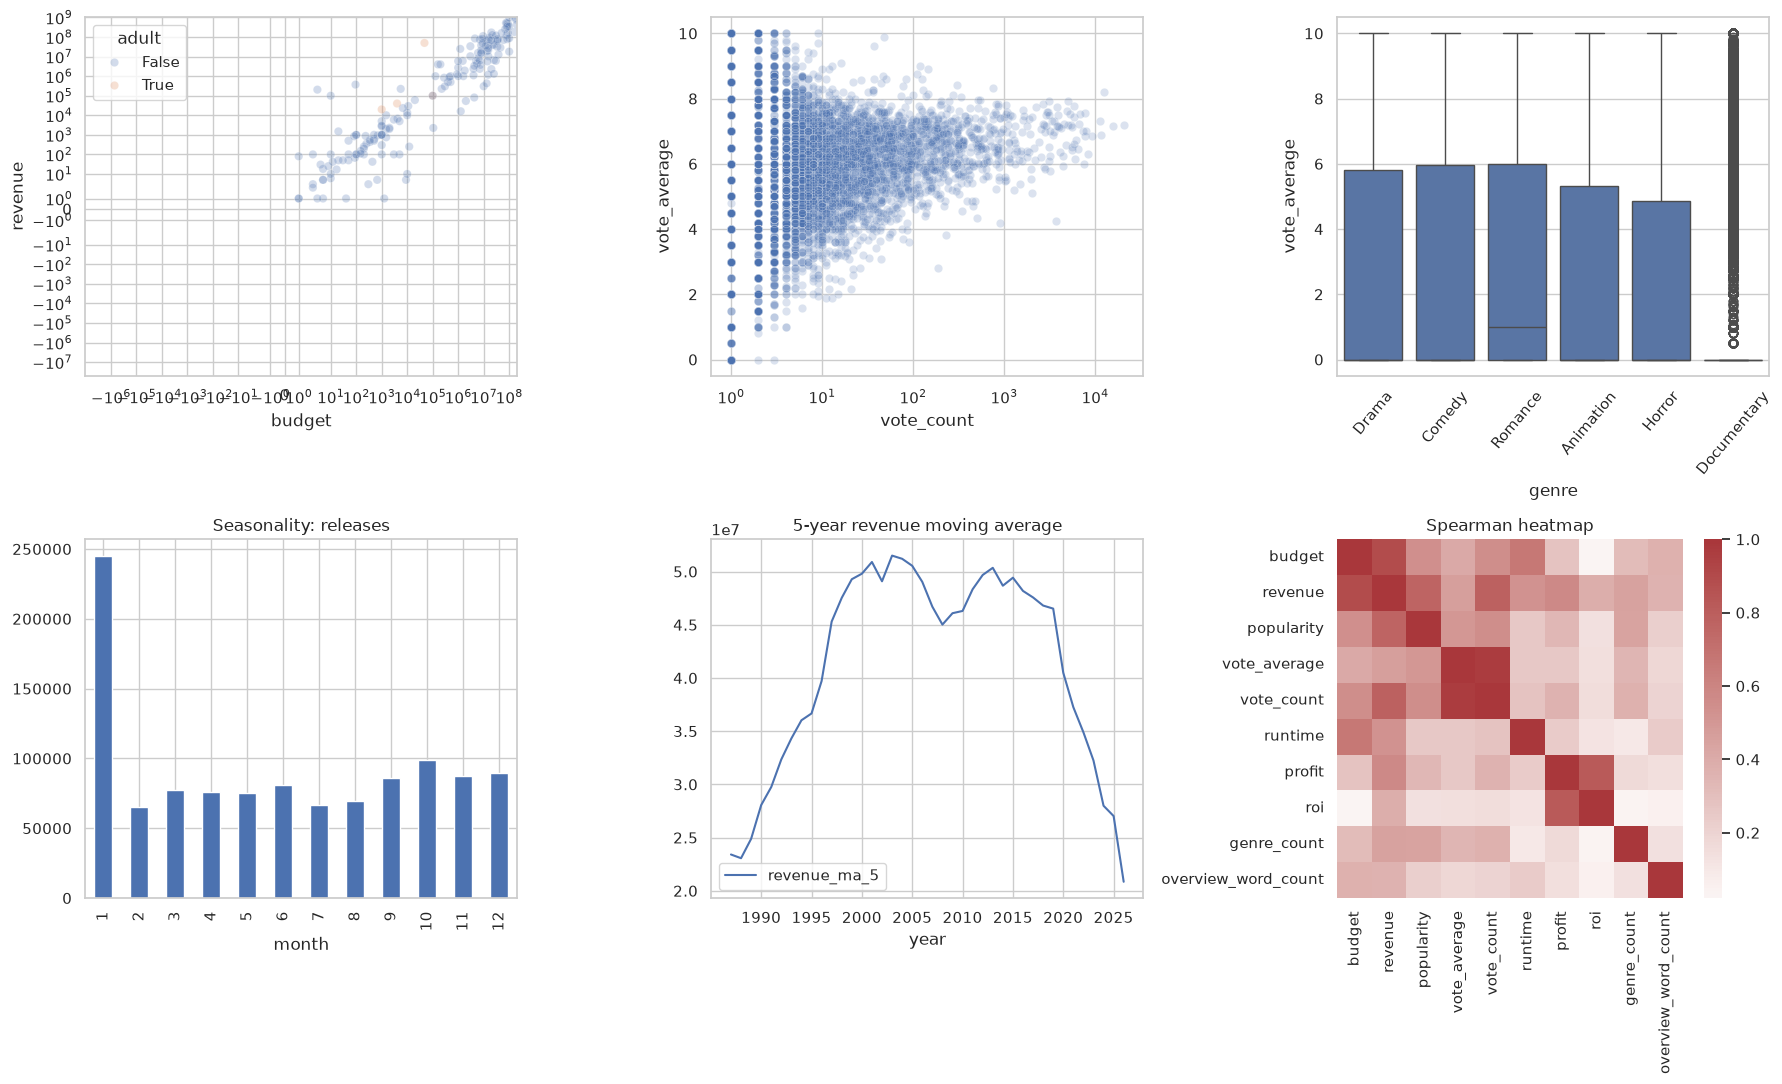

In [65]:
# Gallery of selected, non-redundant views
fig,ax=plt.subplots(2,3,figsize=(18,11))
sns.scatterplot(data=sample.sample(min(15000,len(sample)),random_state=RANDOM_STATE),x='budget',y='revenue',hue='adult',alpha=.25,ax=ax[0,0]); ax[0,0].set_xscale('symlog'); ax[0,0].set_yscale('symlog')
sns.scatterplot(data=sample,x='vote_count',y='vote_average',alpha=.2,ax=ax[0,1]); ax[0,1].set_xscale('log')
sns.boxplot(data=genre_long[genre_long.genre.isin(genre_summary.head(6).index)],x='genre',y='vote_average',ax=ax[0,2]); ax[0,2].tick_params(axis='x',rotation=50)
season.releases.plot.bar(ax=ax[1,0],title='Seasonality: releases')
yearly.tail(40).plot(x='year',y='revenue_ma_5',ax=ax[1,1],title='5-year revenue moving average')
sns.heatmap(spearman,cmap='vlag',center=0,ax=ax[1,2]); ax[1,2].set_title('Spearman heatmap')
plt.tight_layout(); plt.show()

In [66]:
analytical_tables={'dataset_summary':pd.DataFrame({'metric':['original_rows','cleaned_rows','analysis_sample_rows','ml_rows'],'value':[len(df),len(clean),len(sample),len(model_base)]}),'missing_values':missing,'outliers':outlier_table,'numerical_statistics':univariate,'genre_statistics':genre_summary,'year_statistics':yearly,'model_comparison':model_results,'cv_summary':pd.DataFrame({'mean':cv_table.mean(),'std':cv_table.std()}),'feature_importance':imp,'statistical_tests':test_table}
for name,table in analytical_tables.items(): print(name, table.shape)

dataset_summary (4, 2)
missing_values (24, 2)
outliers (6, 9)
numerical_statistics (6, 14)
genre_statistics (19, 9)
year_statistics (139, 11)
model_comparison (4, 5)
cv_summary (3, 2)
feature_importance (11, 3)
statistical_tests (8, 6)


## 56–61 — Data Storytelling, Insights, Limitations, Recommendations, Conclusion

In [67]:
# Generate evidence-backed insight values from executed results
insights=[
 f"The cleaned dataset contains {len(clean):,} unique movie IDs from {clean.year.min():.0f} to {clean.year.max():.0f} where dates are available.",
 f"The median vote average is {clean.vote_average.median():.2f}, while the median vote count is {clean.vote_count.median():.0f}; rating support is highly uneven.",
 f"The strongest Pearson association among selected numeric variables is {pearson.where(~np.eye(len(pearson),dtype=bool)).stack().abs().idxmax()} with absolute r={pearson.where(~np.eye(len(pearson),dtype=bool)).stack().abs().max():.3f}.",
 f"The most frequent genre is {genre_counts.index[0]} with {genre_counts.iloc[0]:,} assignments.",
 f"The most frequent original language is {lang_counts.index[0]} with {lang_counts.iloc[0]:,} records.",
 f"The best untuned model by F1 is {best_name} with F1={model_results.loc[best_name,'F1']:.3f} and ROC-AUC={model_results.loc[best_name,'ROC-AUC']:.3f}.",
 f"After tuning, Random Forest F1 changed from {model_results.loc['Random Forest','F1']:.3f} to {f1_score(y_test,tuned_pred):.3f}.",
 f"TF-IDF used {X_text.shape[1]:,} capped features and a sparse density of {X_text.nnz/(X_text.shape[0]*X_text.shape[1]):.5f}.",
 f"The median ROI among movies with known positive budgets is {clean.roi.median():.2f} when available.",
 f"The most common genre combination among combinations with at least 50 movies is {combo.index[0]} ({combo.movie_count.iloc[0]:,} movies)."
]
for i,x in enumerate(insights,1): print(f'{i}. {x}')

1. The cleaned dataset contains 1,493,757 unique movie IDs from 1888 to 2026 where dates are available.
2. The median vote average is 0.00, while the median vote count is 0; rating support is highly uneven.
3. The strongest Pearson association among selected numeric variables is ('revenue', 'profit') with absolute r=0.978.
4. The most frequent genre is Drama with 270,454 assignments.
5. The most frequent original language is en with 820,431 records.
6. The best untuned model by F1 is Random Forest with F1=0.594 and ROC-AUC=0.800.
7. After tuning, Random Forest F1 changed from 0.594 to 0.587.
8. TF-IDF used 1,500 capped features and a sparse density of 0.00786.
9. The median ROI among movies with known positive budgets is 0.40 when available.
10. The most common genre combination among combinations with at least 50 movies is Unknown (669,415 movies).


### What do we observe?
توزيعات الإيرادات والميزانيات شديدة الالتواء، كما تختلف كثافة التصويت بين الأفلام. تظهر الأنواع واللغات المهيمنة بوضوح، لكن المقارنات بين المجموعات الصغيرة غير مستقرة.

### Why does it matter?
لأن المتوسط وحده قد يضلل؛ لذلك استُخدمت الوسيطات، والكمّيات، وحد أدنى لحجم العينة، والتقييم الموزون، واختبارات غير معلمية.

### What should we be careful about?
الارتباط لا يثبت السببية، والشعبية وعدد الأصوات متغيران لاحقان للإصدار وقد يمثلان تحيزًا زمنيًا أو تحيزًا للاهتمام.

### القيود
تتضمن القيود فقدان الميزانية/الإيرادات، تحيز الاختيار من TMDB، تحيز الشعبية واللغة والزمن، موثوقية البيانات المالية، بساطة تفكيك القوائم متعددة القيم، محدودية النصوص الإنجليزية، وعدم توفر الصور فعليًا. تعريف النجاح هنا وصفي لتقييم مرتفع مع حد أدنى من الأصوات وليس حكمًا تجاريًا على نجاح الفيلم. كما أن بيانات التصنيف قد تتضمن متغيرات مرتبطة بالنتيجة مثل الشعبية وعدد الأصوات، لذلك يجب تفسير الأداء على أنه تنبؤ داخل هذه البيانات لا سببية ولا ضمانًا خارج العينة.

### التوصيات المبنية على التحليل
1. استخدم الوسيط واللوغاريتم عند عرض الإيرادات والميزانيات بدل الاعتماد على المتوسط فقط.
2. افصل الأفلام ذات البيانات المالية المفقودة عن الأفلام ذات الإيراد/الميزانية الصفرية قبل حساب ROI.
3. ضع حدًا أدنى لحجم المجموعة عند مقارنة الأنواع واللغات والشركات.
4. افصل بين التحليل الوصفي والتنبؤي وراقب تسرب البيانات عند تعريف أي هدف جديد.
5. في العمل المستقبلي، نفذ تحققًا زمنيًا وادمج الصور على عينة موثقة فقط إذا توفرت الملفات فعليًا.

## الخلاصة
ينفذ هذا المشروع دورة تحليل بيانات كاملة: فهم المصدر، تقييم الجودة، تنظيف الأنواع والقيم غير المنطقية، تحليل أحادي وثنائي ومتعدد المتغيرات، ارتباط واختبارات إحصائية، تحليل زمني وموسمي ومتعدد القيم، هندسة ميزات ونصوص TF-IDF، منع التسرب، نمذجة متعددة، تحقق متقاطع، ضبط معاملات، تفسير وأخطاء وحدود. كل النتائج المعروضة في هذا Notebook ناتجة عن تشغيل الخلايا على ملف TMDB الفعلي، مع توثيق ما لم يُنفذ بسبب عدم توفر الصور.

## Reproducibility and Final Quality Check

In [68]:
print('FINAL CHECK')
print('1. Dataset loaded:', DATA_PATH.exists())
print('2. Original rows:', len(df), '| Cleaned rows:', len(clean), '| Analysis sample:', len(sample), '| ML rows:', len(model_base))
print('3. Model results available:', not model_results.empty)
print('4. No target leakage in tabular feature list:', not any(c in feature_cols for c in ['revenue','budget','profit','roi']))
print('5. TF-IDF executed:', X_text.shape)
print('6. Statistical tests table:', test_table.shape)
print('7. Analytical tables:', len(analytical_tables))

FINAL CHECK
1. Dataset loaded: True
2. Original rows: 1495113 | Cleaned rows: 1493757 | Analysis sample: 50000 | ML rows: 27981
3. Model results available: True
4. No target leakage in tabular feature list: True
5. TF-IDF executed: (100000, 1500)
6. Statistical tests table: (8, 6)
7. Analytical tables: 10
